# Notebook 05 · Segmentation : RFM du cours et clustering comportemental

**Pourquoi ce notebook ?** Le comité marketing impose de **choisir un segment** et de chiffrer des recommandations, comme le segment « Decel » au Projet 1. Les scores des modèles n'existent pas encore : on prépare le choix à partir du seul **comportement d'achat observé** sur les 12 mois qui précèdent le 1er août 2020. Le notebook 07 croisera ensuite segments et scores.

**Fil conducteur**
1. Segmentation **RFM** du cours : R, F, M, deux façons de fixer les seuils (tertiles ou seuils métier), 27 cases, puis 7 segments actionnables.
2. **Profil** de chaque segment : poids, panier, remise, joignabilité par e-mail, **taux de rachat en août** (train), répartition train / test.
3. **Clustering complémentaire** (ACP, K-Means, CAH de Ward, modèle de réaffectation) : voit-il autre chose que le RFM ?
4. **Candidats** pour le segment cible, critères explicites, dimensionnement du test A/B, **recommandation**.

**Règles du jeu** : la cible ne sert qu'à *décrire* les segments, jamais à les fabriquer ; seuils appris sur le train, même règle appliquée au test ; cadre du cours uniquement (slides 22-28 RFM, 31-47 clustering, 74-76 test A/B). La règle d'affectation vit dans `segments.py` (fonction `assign_rfm`), que le notebook 07 réutilisera.

In [1]:
import os, re, warnings
os.environ.update(OMP_NUM_THREADS='2', OPENBLAS_NUM_THREADS='2', VECLIB_MAXIMUM_THREADS='2', MKL_NUM_THREADS='2')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.power import NormalIndPower
threadpool_limits(2)          # machine partagée : 2 fils au plus
import common as c
import segments as sg
c.set_style()
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)

def fr(x, d=0):               # 12 345,6 (espace insécable, virgule décimale)
    return f"{x:,.{d}f}".replace(',', '\u00a0').replace('.', ',')
def pc(x, d=1):               # x déjà en %
    return f"{x:.{d}f}\u00a0%".replace('.', ',')
def dec(t):               # 0.55 -> 0,55 (uniquement entre deux chiffres)
    return re.sub(r'(?<=\d)\.(?=\d)', ',', t)
def say(t): display(Markdown(dec(t)))
def savefig(fig, name):
    c.save_fig(fig, name); plt.show()

SEG_FR = {'Top': 'Top (meilleurs clients)', 'Good': 'Good (bons clients)', 'Decel': 'Decel (décélération)',
          'Small': 'Small (petits clients)', 'Weak': 'Weak (clients faibles)', 'New': 'New (nouveaux)', 'Inactive': 'Inactive (inactifs)'}
SEG_COLORS = {'Top': c.BLUE, 'Good': c.GREEN, 'Decel': c.ACCENT, 'Small': c.PURPLE, 'Weak': c.GREY, 'New': '#d9a900', 'Inactive': '#8d8b85'}
ORDER = sg.SEGMENT_ORDER

In [2]:
Xtr, Xte = c.load_features('train'), c.load_features('test')
y = c.load_target().reindex(Xtr.index)
base = y.mean()
folds = c.get_folds().reindex(Xtr.index)
say(f"**Train** : {fr(len(Xtr))} clients, taux de rachat en août **{pc(100*base, 2)}** ({fr(y.sum())} rachats). "
    f"**Test** : {fr(len(Xte))} clients, sans cible. Variables : {Xtr.shape[1]} colonnes issues du notebook 02 (photo au 01/08/2020).")

**Train** : 160 424 clients, taux de rachat en août **7,72 %** (12 392 rachats). **Test** : 40 106 clients, sans cible. Variables : 100 colonnes issues du notebook 02 (photo au 01/08/2020).

## 1. Segmentation RFM (slides 23-28)

**Lien avec le cours** : slide 23 (R, F, M), slide 24 (3 niveaux par dimension, grille FM), slide 25 (27 segments), slide 26 (regroupement en Top, Good, Decel, Small, Weak, New, Inactive), slide 27 (seuils par quantiles ou seuils métier).

Trois indicateurs, calculés sur les **tickets d'achat** (retours exclus, comme dans le notebook 02) :
- **R** : `recency_days`, jours depuis le dernier achat ;
- **F** : `n_tickets_all`, nombre de tickets sur 12 mois ;
- **M** : `spend_all`, montant dépensé sur 12 mois (paniers plafonnés au P99,9 par le notebook 02).

### 1.1 Cas particuliers traités avant la notation : Inactive et New
Comme au Projet 1 (clientes sans achat de la période exclues, nouvelles clientes à part), deux populations ne se notent pas sur R, F, M :
- **Inactive** : aucun achat depuis plus de 180 jours, la moitié de l'historique observé. Pour un supermarché, six mois sans passage = client perdu.
- **New** : premier ticket observé il y a moins de 90 jours. Avec si peu d'historique, F et M ne veulent rien dire (un client arrivé la semaine dernière ne peut pas être « fréquent »). Limite : l'historique ne dure que 12 mois, un « New » peut être un ancien client qui revient.

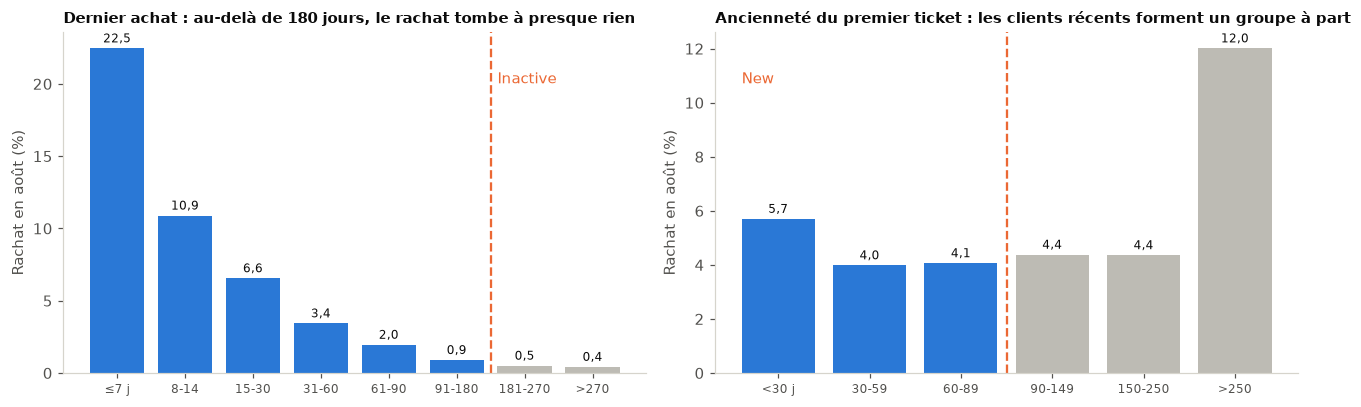

**Lecture** : parmi les clients qui n'ont pas acheté depuis plus de 180 jours, 0,5 % rachètent en août (base : 7,7 %). Parmi les non-inactifs, ceux dont le premier ticket a moins de 90 jours rachètent 4,6 % avec en moyenne 2,7 ticket(s) : un profil qu'on ne peut pas confondre avec un petit client installé. Inactive = 25,3 % de la base, New = 6,2 %.

In [3]:
rb = pd.cut(Xtr['recency_days'], [-1, 7, 14, 30, 60, 90, 180, 270, 400], labels=['≤7 j', '8-14', '15-30', '31-60', '61-90', '91-180', '181-270', '>270'])
r_rec = y.groupby(rb).agg(['mean', 'size'])
nin = ~sg.inactive_mask(Xtr)
tb = pd.cut(Xtr.loc[nin, 'tenure_obs_days'], [-1, 29, 59, 89, 149, 250, 400], labels=['<30 j', '30-59', '60-89', '90-149', '150-250', '>250'])
r_ten = y[nin].groupby(tb).agg(['mean', 'size'])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, r, ttl, cut in [(axes[0], r_rec, 'Dernier achat : au-delà de 180 jours, le rachat tombe à presque rien', 5.5),
                        (axes[1], r_ten, "Ancienneté du premier ticket : les clients récents forment un groupe à part", 2.5)]:
    cols = [c.GREY if i > cut else c.BLUE for i in range(len(r))]
    b = ax.bar(r.index.astype(str), 100 * r['mean'], color=cols)
    ax.bar_label(b, labels=[f"{100*v:.1f}".replace('.', ',') for v in r['mean']], padding=2, fontsize=8)
    ax.set_title(ttl, fontsize=10, loc='left'); ax.set_ylabel('Rachat en août (%)')
    ax.tick_params(axis='x', labelsize=8)
axes[0].axvline(5.5, color=c.ACCENT, ls='--'); axes[0].text(5.6, axes[0].get_ylim()[1] * .85, 'Inactive', color=c.ACCENT)
axes[1].axvline(2.5, color=c.ACCENT, ls='--'); axes[1].text(-0.4, axes[1].get_ylim()[1] * .85, 'New', color=c.ACCENT)
fig.tight_layout(); savefig(fig, '05_regles_new_inactive')
say(f"**Lecture** : parmi les clients qui n'ont pas acheté depuis plus de 180 jours, {pc(100*y[Xtr['recency_days'] > 180].mean())} rachètent en août "
    f"(base : {pc(100*base)}). Parmi les non-inactifs, ceux dont le premier ticket a moins de {sg.NEW_DAYS} jours rachètent {pc(100*y[sg.new_mask(Xtr)].mean())} "
    f"avec en moyenne {Xtr.loc[sg.new_mask(Xtr), 'n_tickets_all'].mean():.1f} ticket(s) : un profil qu'on ne peut pas confondre avec un petit client installé. "
    f"Inactive = {pc(100*sg.inactive_mask(Xtr).mean())} de la base, New = {pc(100*sg.new_mask(Xtr).mean())}.")

### 1.2 Deux façons de fixer les seuils (slide 27)
- **Quantiles (tertiles)** : on coupe chaque dimension en trois tiers égaux, appris **sur le train** (clients notés, hors New et Inactive). Objectif : des niveaux équilibrés, sans jugement métier.
- **Seuils métier** : bornes rondes qui parlent au marketing, fixées *avant* de regarder le rachat. R : ≤ 14 jours (deux cycles de courses), 15-60 jours (comme le seuil de 60 jours du Projet 1), au-delà. F : ≤ 5 tickets (moins d'un passage tous les deux mois), 6-24, ≥ 25 (au moins un passage tous les quinze jours). M : ≤ 150 € par an (quelques paniers), 151-1 000 €, > 1 000 € (environ 20 € par semaine).

In [4]:
th_b, th_q = sg.BUSINESS_THRESHOLDS, sg.fit_thresholds(Xtr)
scored = sg.scored_mask(Xtr)
def bounds(dim, th, lev):
    t = th[dim]
    if dim == 'R':
        a, b = t['high_max_days'], t['medium_max_days']
        return {'High': f"≤ {a:g} j", 'Medium': f"{a:g} < R ≤ {b:g} j", 'Low': f"> {b:g} j"}[lev]
    a, b = t['low_max'], t['medium_max']
    u = ' €' if dim == 'M' else ' tickets'
    return {'Low': f"≤ {a:,.0f}{u}", 'Medium': f"{a:,.0f} < x ≤ {b:,.0f}{u}", 'High': f"> {b:,.0f}{u}"}[lev].replace(',', ' ')
rows = []
for dim, dname in [('R', 'Récence'), ('F', 'Fréquence'), ('M', 'Montant')]:
    for lev, lname in [('High', 'Haut'), ('Medium', 'Moyen'), ('Low', 'Bas')]:
        row = {('', 'Dimension'): dname, ('', 'Niveau'): lname + (' (récent)' if dim == 'R' and lev == 'High' else '')}
        for approach, th, an in [('business', th_b, 'Seuils métier'), ('quantiles', th_q, 'Tertiles')]:
            lv = sg.rfm_levels(Xtr[scored], approach, th)[dim]
            m = lv == lev
            row[(an, 'Bornes')] = bounds(dim, th, lev)
            row[(an, '% clients notés')] = round(100 * m.mean(), 1)
            row[(an, 'Rachat (%)')] = round(100 * y[scored][m].mean(), 2)
        rows.append(row)
level_tab = pd.DataFrame(rows).set_index([('', 'Dimension'), ('', 'Niveau')])
level_tab.index.names = ['Dimension', 'Niveau']
level_tab

(Seuils métier, Bornes)  (Seuils métier, % clients notés)  (Seuils métier, Rachat (%))  (Tertiles, Bornes)  (Tertiles, % clients notés)  (Tertiles, Rachat (%))
Dimension Niveau                                                                                                                                                                       
Récence   Haut (récent)                  ≤ 14 j                              43.8                        19.98               ≤ 8 j                         34.4                   22.34
          Moyen                   14 < R ≤ 60 j                              29.0                         5.49        8 < R ≤ 45 j                         32.4                    7.56
          Bas                            > 60 j                              27.1                         1.26              > 45 j                         33.2                    1.65
Fréquence Haut                     > 24 tickets                              36.1                        22.16        > 27 tickets                         32.6                   23.40
          Moyen              5 < x ≤ 24 tickets                              42.1                         5.68  9 < x ≤ 27 tickets                         31.8                    7.23
          Bas                       ≤ 5 tickets                              21.9                         1.40         ≤ 9 tickets                         35.6                    2.15
Montant   Haut                        > 1 000 €                              37.7                        20.45           > 1 179 €                         33.3                   21.64
          Moyen               150 < x ≤ 1 000 €                              45.0                         5.97   335 < x ≤ 1 179 €                         33.3                    7.96
          Bas                           ≤ 150 €                              17.3                         1.66             ≤ 335 €                         33.3                    2.46

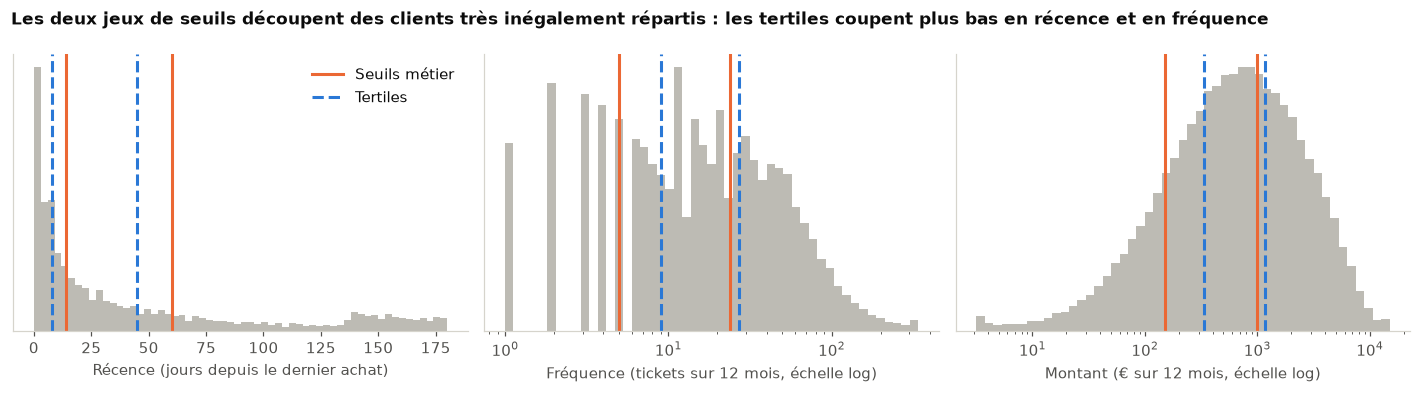

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
d = Xtr[scored]
specs = [('recency_days', 'R', 'Récence (jours depuis le dernier achat)', np.linspace(0, 180, 61), False),
         ('n_tickets_all', 'F', 'Fréquence (tickets sur 12 mois, échelle log)', np.logspace(0, np.log10(340), 50), True),
         ('spend_all', 'M', 'Montant (€ sur 12 mois, échelle log)', np.logspace(0.5, np.log10(15000), 50), True)]
for ax, (col, dim, lab, bins, lg) in zip(axes, specs):
    ax.hist(d[col].clip(lower=bins[0]), bins=bins, color=c.GREY)
    if lg: ax.set_xscale('log')
    keys = ['high_max_days', 'medium_max_days'] if dim == 'R' else ['low_max', 'medium_max']
    for k_, ls, colr, nm in [(0, '-', c.ACCENT, 'métier'), (0, '--', c.BLUE, 'tertiles')]:
        pass
    for i, k_ in enumerate(keys):
        ax.axvline(th_b[dim][k_], color=c.ACCENT, lw=2, label='Seuils métier' if i == 0 else None)
        ax.axvline(th_q[dim][k_], color=c.BLUE, lw=2, ls='--', label='Tertiles' if i == 0 else None)
    ax.set_xlabel(lab); ax.set_yticks([])
axes[0].legend(frameon=False, loc='upper right')
fig.suptitle("Les deux jeux de seuils découpent des clients très inégalement répartis : les tertiles coupent plus bas en récence et en fréquence", x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout(); savefig(fig, '05_seuils_rfm')

### 1.3 La grille des 27 cases et le regroupement en segments actionnables (slides 24-26)
F et M sont d'abord combinés en **FM bas / moyen / haut** (grille 3 × 3 de la slide 24), puis croisés avec trois niveaux de récence : cela donne les 9 cases de la slide 25 (RFM 1 à 9), soit les 27 combinaisons R × F × M regroupées. Le graphique montre les 27 combinaisons (colonnes) pour chaque niveau de récence, avec effectif et taux de rachat ; les cadres noirs sont les 9 cases RFM, nommées avec le segment actionnable de la slide 26.

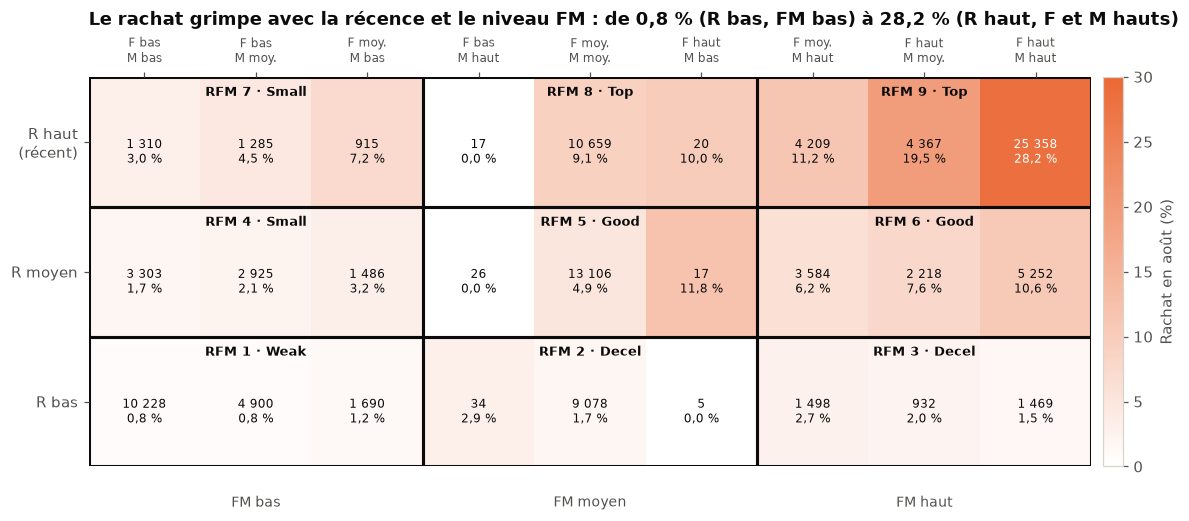

Les 27 combinaisons concernent les 109 891 clients notés (68,5 % de la base) ; les 50 533 autres sont Inactive ou New.

In [6]:
lv = sg.rfm_levels(Xtr, 'business')
combos = [('Low', 'Low'), ('Low', 'Medium'), ('Medium', 'Low'), ('Low', 'High'), ('Medium', 'Medium'), ('High', 'Low'),
          ('Medium', 'High'), ('High', 'Medium'), ('High', 'High')]
rows_R = ['High', 'Medium', 'Low']
ab = {'Low': 'bas', 'Medium': 'moy.', 'High': 'haut'}
nm = np.zeros((3, 9)); rm = np.zeros((3, 9))
for i, rl in enumerate(rows_R):
    for j, (fl, ml) in enumerate(combos):
        m = scored & (lv['R'] == rl) & (lv['F'] == fl) & (lv['M'] == ml)
        nm[i, j], rm[i, j] = m.sum(), 100 * y[m].mean() if m.sum() else np.nan
cmap = LinearSegmentedColormap.from_list('w', ['#ffffff', c.ACCENT])
fig, ax = plt.subplots(figsize=(14, 4.6))
im = ax.imshow(np.nan_to_num(rm), cmap=cmap, vmin=0, vmax=30, aspect='auto')
for i in range(3):
    for j in range(9):
        ax.text(j, i + .08, f"{fr(nm[i, j])}\n{rm[i, j]:.1f} %".replace('.', ','), ha='center', va='center', fontsize=8,
                color=c.INK if rm[i, j] < 20 else 'white')
    for b in range(3):
        cell_no = (2 - i) * 3 + b + 1
        ax.add_patch(Rectangle((3 * b - .5, i - .5), 3, 1, fill=False, ec=c.INK, lw=2))
        ax.text(3 * b + 1, i - .38, f"RFM {cell_no} · {sg.CELL_TO_SEGMENT[str(cell_no)]}", ha='center', va='center', fontsize=8.5, fontweight='bold')
ax.set_xticks(range(9)); ax.set_xticklabels([f"F {ab[f]}\nM {ab[m]}" for f, m in combos], fontsize=8)
ax.set_yticks(range(3)); ax.set_yticklabels(['R haut\n(récent)', 'R moyen', 'R bas']); ax.xaxis.tick_top()
for s_, lab in [(1, 'FM bas'), (4, 'FM moyen'), (7, 'FM haut')]:
    ax.text(s_, 2.78, lab, ha='center', va='center', fontsize=9, color=c.INK2, transform=ax.transData)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, pad=0.01, label='Rachat en août (%)')
ax.set_title(f"Le rachat grimpe avec la récence et le niveau FM : de {rm[2, 0]:.1f} % (R bas, FM bas) à {rm[0, 8]:.1f} % (R haut, F et M hauts)".replace('.', ','), loc='left', pad=34)
savefig(fig, '05_grille_rfm27')
say(f"Les 27 combinaisons concernent les {fr(scored.sum())} clients notés ({pc(100*scored.mean())} de la base) ; les {fr((~scored).sum())} autres sont Inactive ou New.")

**Règles d'affectation retenues** (code : `segments.assign_rfm`, dans cet ordre) :

In [7]:
rules = pd.DataFrame([
    ('Inactive', f"aucun achat depuis plus de {sg.INACTIVE_DAYS} j (ou aucun achat, que des retours)", '—', "Clients perdus : coût de réactivation élevé, ne pas les confondre avec les clients qui décrochent"),
    ('New', f"premier ticket observé il y a moins de {sg.NEW_DAYS} j", '—', "Historique trop court pour juger R, F et M : parcours d'accueil"),
    ('Top', "FM moyen ou haut et R haut", '8, 9', "Meilleurs clients : fidéliser sans brader"),
    ('Good', "FM moyen ou haut et R moyen", '5, 6', "Clients installés, pas venus depuis 2 semaines à 2 mois : à surveiller, relancer au bon moment"),
    ('Decel', "FM moyen ou haut et R bas (61-180 j)", '2, 3', "Bons clients qui s'endorment (slide 26 : « Decelerations »)"),
    ('Small', "FM bas et R haut ou moyen", '4, 7', "Petits clients actifs : développer le panier ou la fréquence"),
    ('Weak', "FM bas et R bas", '1', "Faible valeur, peu actifs : peu d'investissement"),
], columns=['Segment', 'Règle', 'Cases slide 25', 'Lecture marketing']).set_index('Segment')
rules

,Règle,Cases slide 25,Lecture marketing
Segment,,,
Inactive,"aucun achat depuis plus de 180 j (ou aucun achat, que des retours)",—,"Clients perdus : coût de réactivation élevé, ne pas les confondre avec les c..."
New,premier ticket observé il y a moins de 90 j,—,"Historique trop court pour juger R, F et M : parcours d'accueil"
Top,FM moyen ou haut et R haut,"8, 9",Meilleurs clients : fidéliser sans brader
Good,FM moyen ou haut et R moyen,"5, 6","Clients installés, pas venus depuis 2 semaines à 2 mois : à surveiller, rela..."
Decel,FM moyen ou haut et R bas (61-180 j),"2, 3",Bons clients qui s'endorment (slide 26 : « Decelerations »)
Small,FM bas et R haut ou moyen,"4, 7",Petits clients actifs : développer le panier ou la fréquence
Weak,FM bas et R bas,1,"Faible valeur, peu actifs : peu d'investissement"


In [8]:
seg_tr, seg_te = sg.assign_rfm(Xtr), sg.assign_rfm(Xte)                    # seuils métier (retenus)
seg_q_tr, seg_q_te = sg.assign_rfm(Xtr, 'quantiles', th_q), sg.assign_rfm(Xte, 'quantiles', th_q)
cmp = pd.DataFrame({'Métier : % clients': 100 * seg_tr.value_counts(normalize=True), 'Métier : rachat (%)': 100 * y.groupby(seg_tr).mean(),
                    'Tertiles : % clients': 100 * seg_q_tr.value_counts(normalize=True), 'Tertiles : rachat (%)': 100 * y.groupby(seg_q_tr).mean()}).reindex(ORDER).round(1)
display(cmp)
agree = (seg_tr == seg_q_tr).mean()
say(f"Les deux approches donnent la **même étiquette pour {pc(100*agree)} des clients** et le même ordre de rachat (Top > Good > New > Small > Decel > Weak > Inactive). "
    f"Les tertiles réduisent Top ({pc(cmp.loc['Top', 'Tertiles : % clients'])} des clients contre {pc(cmp.loc['Top', 'Métier : % clients'])}) et gonflent Small et Weak, parce que leurs bornes de fréquence et de montant sont plus hautes "
    f"(F bas ≤ {th_q['F']['low_max']:g} tickets contre ≤ {th_b['F']['low_max']:g}, M bas ≤ {th_q['M']['low_max']:.0f} € contre ≤ {th_b['M']['low_max']:.0f} €), et plus basses en récence (R haut ≤ {th_q['R']['high_max_days']:g} j contre ≤ {th_b['R']['high_max_days']:g}).")
display(pd.crosstab(seg_tr.rename('Seuils métier'), seg_q_tr.rename('Tertiles')))

,Métier : % clients,Métier : rachat (%),Tertiles : % clients,Tertiles : rachat (%)
rfm_segment,,,,
Top,27.8,21.2,20.2,25.0
Good,15.1,6.5,13.8,10.0
Decel,8.1,1.8,6.3,2.7
Small,7.0,2.9,11.8,4.4
Weak,10.5,0.8,16.5,1.2
New,6.2,4.6,6.2,4.6
Inactive,25.3,0.5,25.3,0.5


Les deux approches donnent la **même étiquette pour 81,5 % des clients** et le même ordre de rachat (Top > Good > New > Small > Decel > Weak > Inactive). Les tertiles réduisent Top (20,2 % des clients contre 27,8 %) et gonflent Small et Weak, parce que leurs bornes de fréquence et de montant sont plus hautes (F bas ≤ 9 tickets contre ≤ 5, M bas ≤ 335 € contre ≤ 150 €), et plus basses en récence (R haut ≤ 8 j contre ≤ 14).

Tertiles,Top,Good,Decel,Small,Weak,New,Inactive
Seuils métier,,,,,,,
Top,32442,7484,0,4704,0,0,0
Good,0,14606,2735,5198,1664,0,0
Decel,0,0,7312,0,5704,0,0
Small,0,0,0,9017,2207,0,0
Weak,0,0,0,0,16818,0,0
New,0,0,0,0,0,9995,0
Inactive,0,0,0,0,0,0,40538


**Choix : seuils métier (par défaut dans `assign_rfm`).** Mêmes ordres de grandeur, mais (1) les bornes sont lisibles par le marketing (« moins de 15 jours », « plus de 1 000 € par an ») et alignées sur des paliers de fidélité, comme le recommande la slide 27 ; (2) elles ne bougent pas quand la base change, donc le segment « Good » de juillet est comparable à celui d'août ; (3) la récence est bimodale (beaucoup de clients très récents, beaucoup de clients partis), si bien que ses tertiles tombent à des valeurs peu parlantes pour un marketeur. L'approche par tertiles reste disponible (`approach='quantiles'`) comme contrôle de robustesse.

## 2. Profil des segments RFM

Pour chaque segment : poids (clients, chiffre d'affaires), comportement (panier, fréquence, remise), profil (prix, joignabilité), puis **rachat en août** (train) : taux, intervalle de confiance, lift, nombre de rachats et part des rachats totaux. Le **CA** est le montant dépensé sur 12 mois ; le **panier** est le CA divisé par le nombre de tickets.

In [9]:
def profile(X, y, lab, order, Xt=None, labt=None):
    d = X.assign(_y=y.values, _lab=pd.Series(lab).values)
    g = d.groupby('_lab', observed=True)
    n = g.size()
    out = pd.DataFrame({'n_clients': n})
    out['pct_clients'] = 100 * n / len(d)
    out['pct_ca'] = 100 * g['spend_all'].sum() / d['spend_all'].sum()
    out['ca_per_client'] = g['spend_all'].mean()
    out['tickets_per_client'] = g['n_tickets_all'].mean()
    out['basket_mean'] = g['spend_all'].sum() / g['n_tickets_all'].sum()
    out['active_months'] = g['n_active_months'].mean()
    out['recency_median'] = g['recency_days'].median()
    out['tickets_median'] = g['n_tickets_all'].median()
    out['discount_rate_pct'] = 100 * d.assign(_dr=d['discount_rate_all'].clip(lower=0)).groupby('_lab', observed=True)['_dr'].mean()
    known = d[d['price_segment'] != 'INCONNU']
    out['price_segment_top'] = known.groupby('_lab', observed=True)['price_segment'].agg(lambda s: s.value_counts().idxmax())
    out['price_segment_known_pct'] = 100 * (d['price_segment'] != 'INCONNU').groupby(d['_lab'], observed=True).mean()
    out['pct_email'] = 100 * g['has_email'].mean()
    out['pct_card'] = 100 * g['has_card'].mean()
    k = g['_y'].sum()
    out['rebuy_pct'] = 100 * k / n
    lo, hi = proportion_confint(k, n, method='wilson')
    out['rebuy_ci_low'], out['rebuy_ci_high'] = 100 * lo, 100 * hi
    out['lift'] = out['rebuy_pct'] / (100 * y.mean())
    out['rebuys'] = k
    out['pct_rebuys'] = 100 * k / y.sum()
    if Xt is not None:
        nt = pd.Series(labt).value_counts()
        out['n_clients_test'] = nt.reindex(out.index)
        out['pct_clients_test'] = 100 * out['n_clients_test'] / len(Xt)
        out['rebuys_expected_test'] = out['n_clients_test'] * out['rebuy_pct'] / 100
    out.index.name = 'segment'
    return out.reindex(order)

FR = {'n_clients': 'Clients', 'pct_clients': '% clients', 'pct_ca': '% CA', 'ca_per_client': 'CA / client (€)', 'tickets_per_client': 'Tickets / an',
      'basket_mean': 'Panier moyen (€)', 'active_months': 'Mois actifs (/12)', 'recency_median': 'Récence médiane (j)', 'tickets_median': 'Tickets médian',
      'discount_rate_pct': 'Remise (%)', 'price_segment_top': 'Segment de prix dominant', 'price_segment_known_pct': '% prix connu', 'pct_email': '% avec e-mail',
      'pct_card': '% carte fidélité', 'rebuy_pct': 'Rachat août (%)', 'rebuy_ci_low': 'IC95 bas', 'rebuy_ci_high': 'IC95 haut', 'lift': 'Lift', 'rebuys': 'Rachats',
      'pct_rebuys': '% des rachats', 'n_clients_test': 'Clients test', 'pct_clients_test': '% clients test', 'rebuys_expected_test': 'Rachats attendus (test)'}
def show(p, cols=None):
    q = p[cols] if cols else p
    return q.rename(columns=FR).round(2 if 'lift' in q else 1)

prof_rfm = profile(Xtr, y, seg_tr, ORDER, Xte, seg_te)
show(prof_rfm, ['n_clients', 'pct_clients', 'pct_ca', 'ca_per_client', 'tickets_per_client', 'basket_mean', 'active_months', 'discount_rate_pct', 'price_segment_top', 'price_segment_known_pct', 'pct_email', 'pct_card'])

,Clients,% clients,% CA,CA / client (€),Tickets / an,Panier moyen (€),Mois actifs (/12),Remise (%),Segment de prix dominant,% prix connu,% avec e-mail,% carte fidélité
segment,,,,,,,,,,,,
Top,44630,27.8,67.5,2320.0,48.7,47.6,9.9,5.1,Mixte,51.6,60.9,5.8
Good,24203,15.1,17.2,1087.1,22.8,47.7,8.1,4.1,Mixte,50.6,57.7,3.2
Decel,13016,8.1,6.8,804.1,17.9,44.8,6.1,4.2,Mixte,48.2,56.5,2.2
Small,11224,7.0,1.3,171.2,4.8,35.7,3.6,3.5,Mixte,44.5,50.1,2.3
Weak,16818,10.5,1.5,133.7,3.2,41.3,2.4,3.4,Mixte,42.4,50.0,2.0
New,9995,6.2,0.9,145.4,2.7,53.8,1.3,3.3,Mixte,38.1,54.3,1.9
Inactive,40538,25.3,4.8,182.5,4.2,43.8,1.9,3.8,Mixte,29.3,48.6,1.3


In [10]:
show(prof_rfm, ['rebuy_pct', 'rebuy_ci_low', 'rebuy_ci_high', 'lift', 'rebuys', 'pct_rebuys', 'n_clients_test', 'pct_clients_test', 'rebuys_expected_test'])

,Rachat août (%),IC95 bas,IC95 haut,Lift,Rachats,% des rachats,Clients test,% clients test,Rachats attendus (test)
segment,,,,,,,,,
Top,21.19,20.81,21.57,2.74,9455,76.30,11062,27.58,2343.52
Good,6.55,6.24,6.87,0.85,1585,12.79,6104,15.22,399.74
Decel,1.82,1.60,2.07,0.24,237,1.91,3265,8.14,59.45
Small,2.93,2.63,3.26,0.38,329,2.65,2903,7.24,85.09
Weak,0.83,0.71,0.98,0.11,140,1.13,4107,10.24,34.19
New,4.57,4.18,5.00,0.59,457,3.69,2508,6.25,114.67
Inactive,0.47,0.40,0.54,0.06,189,1.53,10157,25.33,47.35


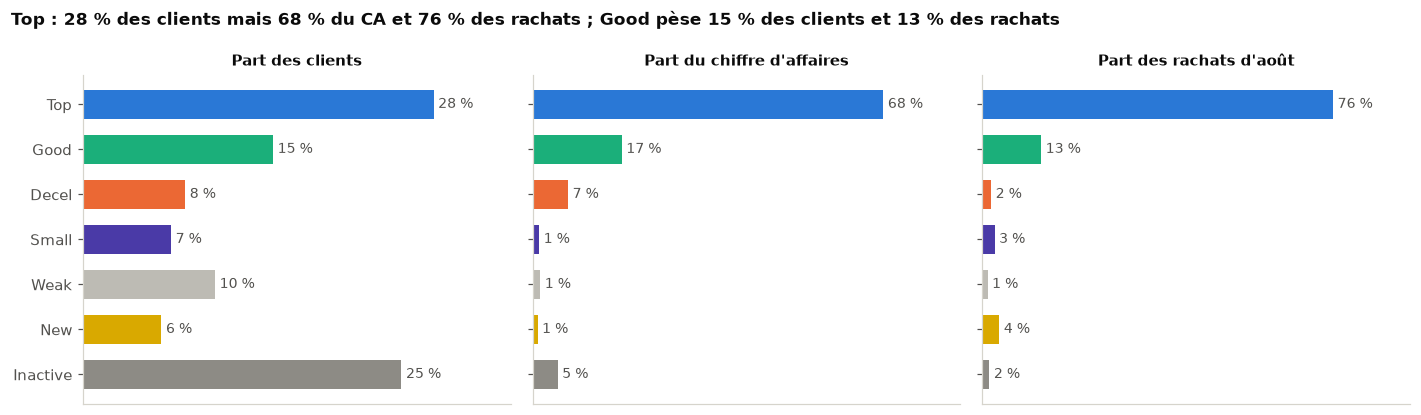

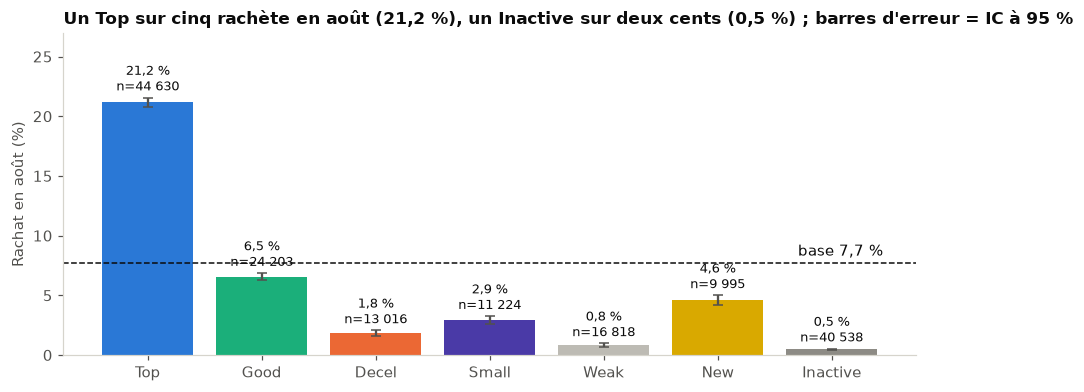

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, col, ttl in zip(axes, ['pct_clients', 'pct_ca', 'pct_rebuys'], ['Part des clients', 'Part du chiffre d\'affaires', "Part des rachats d'août"]):
    b = ax.barh(ORDER, prof_rfm[col], color=[SEG_COLORS[s] for s in ORDER], height=.65)
    ax.bar_label(b, labels=[pc(v, 0) for v in prof_rfm[col]], padding=3, fontsize=9, color=c.INK2)
    ax.set_title(ttl, fontsize=10); ax.set_xlim(0, prof_rfm[col].max() * 1.22); ax.set_xticks([])
axes[0].invert_yaxis()
t, g_ = prof_rfm.loc['Top'], prof_rfm.loc['Good']
fig.suptitle(f"Top : {pc(t.pct_clients, 0)} des clients mais {pc(t.pct_ca, 0)} du CA et {pc(t.pct_rebuys, 0)} des rachats ; Good pèse {pc(g_.pct_clients, 0)} des clients et {pc(g_.pct_rebuys, 0)} des rachats",
             x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout(); savefig(fig, '05_poids_segments')

fig, ax = plt.subplots(figsize=(10, 3.8))
r = prof_rfm
ax.bar(ORDER, r['rebuy_pct'], color=[SEG_COLORS[s] for s in ORDER], yerr=[r['rebuy_pct'] - r['rebuy_ci_low'], r['rebuy_ci_high'] - r['rebuy_pct']], capsize=3, ecolor=c.INK2)
ax.axhline(100 * base, color=c.INK, ls='--', lw=1); ax.text(6.45, 100 * base + .6, f"base {pc(100*base)}", ha='right', color=c.INK)
for i, s in enumerate(ORDER):
    ax.text(i, r.loc[s, 'rebuy_ci_high'] + .6, f"{r.loc[s, 'rebuy_pct']:.1f} %".replace('.', ',') + f"\nn={fr(r.loc[s, 'n_clients'])}", ha='center', fontsize=8.5)
ax.set_ylabel('Rachat en août (%)'); ax.set_ylim(0, r['rebuy_ci_high'].max() * 1.25)
ax.set_title(f"Un Top sur cinq rachète en août ({pc(r.loc['Top', 'rebuy_pct'])}), un Inactive sur deux cents ({pc(r.loc['Inactive', 'rebuy_pct'])}) ; barres d'erreur = IC à 95 %", loc='left', fontsize=11)
savefig(fig, '05_rachat_segments')

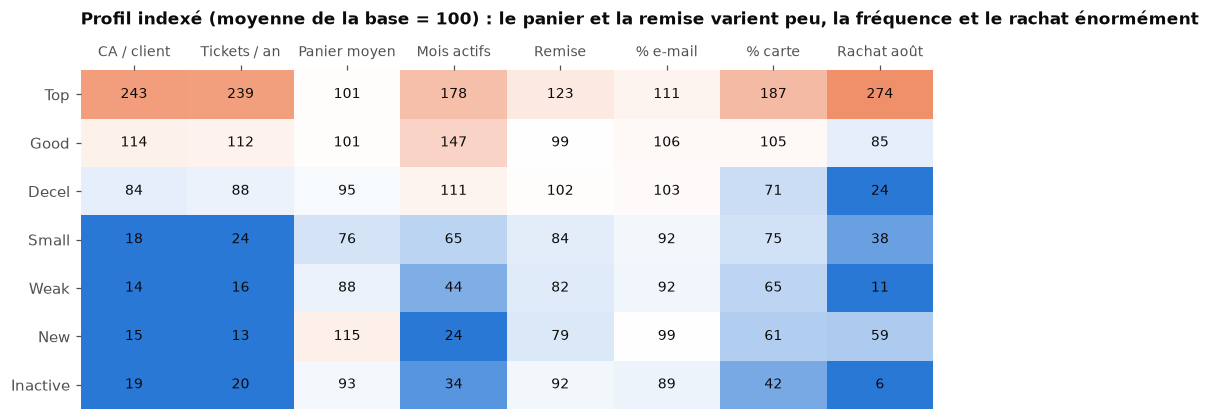

**Lecture** : le panier moyen est quasi constant d'un segment à l'autre (de 36 € à 54 €) : ce qui sépare les clients, c'est **le nombre de passages**, pas le montant dépensé par passage. La part de clients joignables par e-mail va de 48,6 % (Inactive) à 60,9 % (Top) : un e-mail seul n'atteint que 54,7 % de la base. La carte de fidélité est très rare (3,1 % des clients) : elle ne peut pas servir de levier de masse. Le segment de prix est connu pour 29 % à 52 % des clients selon le segment : à lire avec prudence.

In [12]:
kp = [('ca_per_client', 'CA / client'), ('tickets_per_client', 'Tickets / an'), ('basket_mean', 'Panier moyen'), ('active_months', 'Mois actifs'),
      ('discount_rate_pct', 'Remise'), ('pct_email', '% e-mail'), ('pct_card', '% carte'), ('rebuy_pct', 'Rachat août')]
tot = pd.Series({'ca_per_client': Xtr['spend_all'].mean(), 'tickets_per_client': Xtr['n_tickets_all'].mean(), 'basket_mean': Xtr['spend_all'].sum() / Xtr['n_tickets_all'].sum(),
                 'active_months': Xtr['n_active_months'].mean(), 'discount_rate_pct': 100 * Xtr['discount_rate_all'].clip(lower=0).mean(),
                 'pct_email': 100 * Xtr['has_email'].mean(), 'pct_card': 100 * Xtr['has_card'].mean(), 'rebuy_pct': 100 * base})
idx = pd.DataFrame({lab: 100 * prof_rfm[k] / tot[k] for k, lab in kp}).reindex(ORDER)
fig, ax = plt.subplots(figsize=(10, 4))
cm = LinearSegmentedColormap.from_list('d', [c.BLUE, '#ffffff', c.ACCENT])
ax.imshow(np.log2(idx.clip(10, 1000) / 100), cmap=cm, vmin=-2, vmax=2, aspect='auto')
for i in range(idx.shape[0]):
    for j in range(idx.shape[1]):
        ax.text(j, i, f"{idx.iloc[i, j]:.0f}", ha='center', va='center', fontsize=9)
ax.set_xticks(range(idx.shape[1])); ax.set_xticklabels(idx.columns, fontsize=9); ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(ORDER)
ax.spines[:].set_visible(False); ax.xaxis.tick_top()
ax.set_title("Profil indexé (moyenne de la base = 100) : le panier et la remise varient peu, la fréquence et le rachat énormément", loc='left', pad=30, fontsize=11)
savefig(fig, '05_profil_segments')
say(f"**Lecture** : le panier moyen est quasi constant d'un segment à l'autre (de {fr(prof_rfm['basket_mean'].min())} € à {fr(prof_rfm['basket_mean'].max())} €) : "
    f"ce qui sépare les clients, c'est **le nombre de passages**, pas le montant dépensé par passage. "
    f"La part de clients joignables par e-mail va de {pc(prof_rfm['pct_email'].min())} ({prof_rfm['pct_email'].idxmin()}) à {pc(prof_rfm['pct_email'].max())} ({prof_rfm['pct_email'].idxmax()}) : "
    f"un e-mail seul n'atteint que {pc(100*Xtr['has_email'].mean())} de la base. La carte de fidélité est très rare ({pc(100*Xtr['has_card'].mean())} des clients) : elle ne peut pas servir de levier de masse. "
    f"Le segment de prix est connu pour {pc(prof_rfm['price_segment_known_pct'].min(), 0)} à {pc(prof_rfm['price_segment_known_pct'].max(), 0)} des clients selon le segment : à lire avec prudence.")

In [13]:
chk = pd.DataFrame({'Train (%)': prof_rfm['pct_clients'], 'Test (%)': prof_rfm['pct_clients_test']}).round(1)
chk['Écart (pts)'] = (chk['Test (%)'] - chk['Train (%)']).round(2)
display(chk)
say(f"**Train vs test** : la même règle donne des parts quasi identiques (écart maximal {chk['Écart (pts)'].abs().max():.2f} point) : la segmentation est stable, aucun seuil n'a été appris sur le test. "
    f"Les rachats attendus dans le test sont le produit des effectifs du test par les taux observés sur le train (le test n'a pas de cible).")

,Train (%),Test (%),Écart (pts)
segment,,,
Top,27.8,27.6,-0.2
Good,15.1,15.2,0.1
Decel,8.1,8.1,0.0
Small,7.0,7.2,0.2
Weak,10.5,10.2,-0.3
New,6.2,6.3,0.1
Inactive,25.3,25.3,0.0


**Train vs test** : la même règle donne des parts quasi identiques (écart maximal 0,30 point) : la segmentation est stable, aucun seuil n'a été appris sur le test. Les rachats attendus dans le test sont le produit des effectifs du test par les taux observés sur le train (le test n'a pas de cible).

## 3. Clustering complémentaire : que voit-on que le RFM ne voit pas ?

**Lien avec le cours** : slides 32-34 (étapes d'un clustering marketing), 35-36 (ACP, 70-90 % de variance), 37-38 (*l'objectif de la segmentation choisit les variables*), 39-47 (K-Means, CAH, coude, silhouette, interprétation, modèle de réaffectation).

Le RFM ne retient que trois dimensions. Le clustering part de **neuf variables de comportement d'achat** (pas de démographie : slide 38, le profil sert à *interpréter* les classes) : quand vient le client, depuis combien de temps, à quel rythme, avec quel panier, quelle gamme, quelle sensibilité aux remises, à quels moments, dans combien de magasins.

In [14]:
Zraw = sg.cluster_matrix(Xtr)
desc = pd.DataFrame(sg.CLUSTER_FEATURES, columns=['variable', 'description']).set_index('variable')
desc['moyenne'] = Zraw.mean().round(2); desc['écart-type'] = Zraw.std().round(2); desc['manquants'] = Zraw.isna().sum()
display(desc)
rho = Zraw.corr(method='spearman')
off = rho.where(~np.eye(len(rho), dtype=bool)).abs().stack()
r_b = Xtr[['basket_mean_all', 'items_per_ticket_mean']].corr(method='spearman').iloc[0, 1]
say(f"**Sélection** : on écarte les variables redondantes (le notebook 02 a déjà retiré les quasi-doublons). Par exemple le panier moyen et le nombre d'articles par ticket ont un ρ de Spearman de {r_b:.2f} : on garde le panier (en log) et le prix par article pour la gamme. "
    f"Sur les 9 variables retenues, la corrélation absolue la plus forte est {off.max():.2f} ({' / '.join(off.idxmax())}), la moyenne {off.mean():.2f}. "
    f"Le montant total n'est pas retenu : c'est fréquence × panier, déjà présents. Les {int(Zraw.isna().any(axis=1).sum())} clients sans achat sont imputés par la médiane du train (règle du cours, slide 87).")

,description,moyenne,écart-type,manquants
variable,,,,
log_recency,Récence (log du nombre de jours depuis le dernier achat),3.60,1.74,10
log_n_tickets_all,Fréquence (log du nombre de tickets sur 12 mois),2.31,1.22,0
trend_freq_90,Tendance de fréquence (90 derniers jours vs 90 précédents),0.03,0.75,0
log_basket_mean,"Panier moyen (log, €)",3.63,0.87,10
log_price_per_item,"Prix moyen par article (log, €)",1.43,0.42,11
discount_rate_all,Taux de remise global,0.04,0.06,11
share_weekend,Part des tickets le week-end,0.26,0.27,10
share_evening,Part des tickets en soirée (après 18 h),0.20,0.27,10
n_stores,Nombre de magasins fréquentés,1.48,0.90,0


**Sélection** : on écarte les variables redondantes (le notebook 02 a déjà retiré les quasi-doublons). Par exemple le panier moyen et le nombre d'articles par ticket ont un ρ de Spearman de 0,86 : on garde le panier (en log) et le prix par article pour la gamme. Sur les 9 variables retenues, la corrélation absolue la plus forte est 0,68 (log_recency / log_n_tickets_all), la moyenne 0,14. Le montant total n'est pas retenu : c'est fréquence × panier, déjà présents. Les 12 clients sans achat sont imputés par la médiane du train (règle du cours, slide 87).

### 3.1 ACP (slides 35-36)
On standardise (moyenne 0, écart-type 1 : sinon la récence en log domine le taux de remise) puis on projette. On retient assez d'axes pour expliquer **80 %** de la variance (fourchette du cours : 70-90 %). Le cercle des corrélations montre quelles variables fabriquent chaque axe.

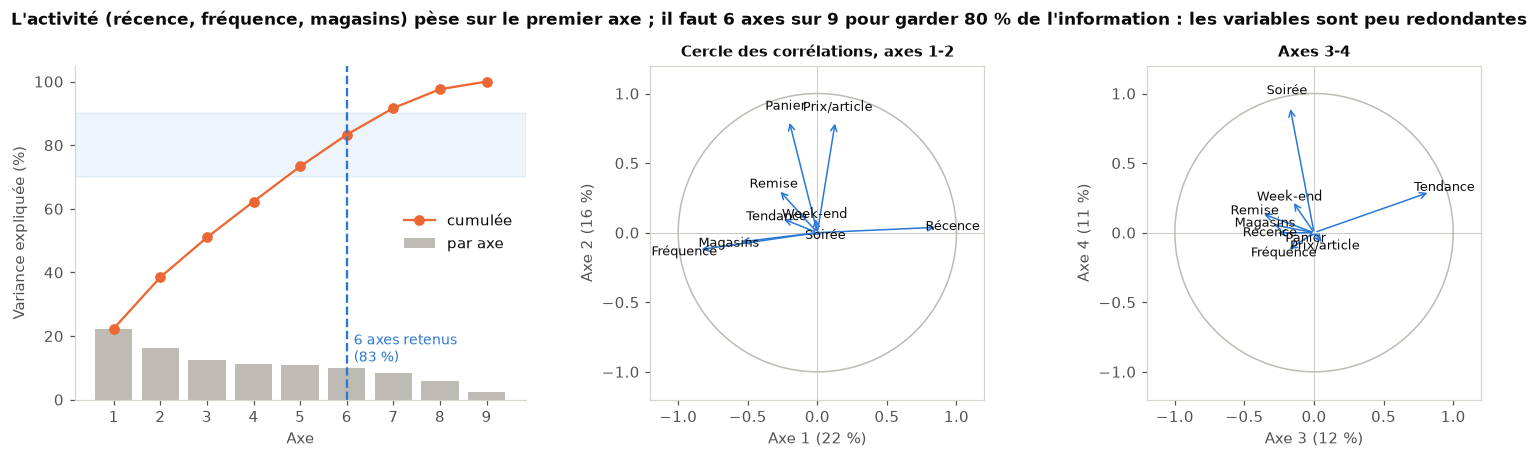

**Lecture des axes** (corrélations variable-axe les plus fortes) : Axe 1 : Récence (+0,87), Fréquence (-0,85), Magasins (-0,57) ; Axe 2 : Panier (+0,81), Prix/article (+0,81), Remise (+0,31) ; Axe 3 : Tendance (+0,84), Remise (-0,38), Magasins (-0,31) ; Axe 4 : Soirée (+0,91), Tendance (+0,29), Week-end (+0,23) ; Axe 5 : Week-end (+0,95), Soirée (-0,25), Remise (-0,11) ; Axe 6 : Remise (+0,79), Magasins (-0,34), Prix/article (-0,27).

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
med = Zraw.median()
S = StandardScaler().fit_transform(Zraw.fillna(med))
pca_full = PCA(random_state=c.SEED).fit(S)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_axes = int(np.searchsorted(cum, 0.80) + 1)
load = pd.DataFrame(pca_full.components_.T * np.sqrt(pca_full.explained_variance_), index=Zraw.columns, columns=[f"Axe {i+1}" for i in range(len(cum))])
short = {'log_recency': 'Récence', 'log_n_tickets_all': 'Fréquence', 'trend_freq_90': 'Tendance', 'log_basket_mean': 'Panier', 'log_price_per_item': 'Prix/article',
         'discount_rate_all': 'Remise', 'share_weekend': 'Week-end', 'share_evening': 'Soirée', 'n_stores': 'Magasins'}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1.1, 1, 1]})
ax = axes[0]
ax.bar(range(1, len(cum) + 1), 100 * pca_full.explained_variance_ratio_, color=c.GREY, label='par axe')
ax.plot(range(1, len(cum) + 1), 100 * cum, 'o-', color=c.ACCENT, label='cumulée')
ax.axhspan(70, 90, color=c.BLUE, alpha=.08); ax.axvline(n_axes, color=c.BLUE, ls='--')
ax.text(n_axes + .15, 12, f"{n_axes} axes retenus\n({100*cum[n_axes-1]:.0f} %)".replace('.', ','), color=c.BLUE, fontsize=9)
ax.set_xlabel('Axe'); ax.set_ylabel('Variance expliquée (%)'); ax.legend(frameon=False, loc='center right'); ax.set_xticks(range(1, len(cum) + 1))
for ax, (a, b) in zip(axes[1:], [(0, 1), (2, 3)]):
    th_ = np.linspace(0, 2 * np.pi, 200); ax.plot(np.cos(th_), np.sin(th_), color=c.GREY, lw=1)
    for v in load.index:
        x_, y_ = load.loc[v].iloc[a], load.loc[v].iloc[b]
        ax.annotate('', (x_, y_), (0, 0), arrowprops=dict(arrowstyle='->', color=c.BLUE))
        ax.text(x_ * 1.12, y_ * 1.12, short[v], fontsize=8.5, ha='center', va='center')
    ax.axhline(0, color=c.GREY, lw=.5); ax.axvline(0, color=c.GREY, lw=.5); ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect('equal')
    ax.set_xlabel(f"Axe {a+1} ({100*pca_full.explained_variance_ratio_[a]:.0f} %)"); ax.set_ylabel(f"Axe {b+1} ({100*pca_full.explained_variance_ratio_[b]:.0f} %)")
    ax.spines[:].set_visible(True)
axes[1].set_title('Cercle des corrélations, axes 1-2', fontsize=10); axes[2].set_title('Axes 3-4', fontsize=10)
fig.suptitle(f"L'activité (récence, fréquence, magasins) pèse sur le premier axe ; il faut {n_axes} axes sur {len(cum)} pour garder 80 % de l'information : les variables sont peu redondantes", x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout(); savefig(fig, '05_acp')
top_l = {a: ', '.join(f"{short[v]} ({load.loc[v, a]:+.2f})" for v in load[a].abs().sort_values(ascending=False).index[:3]) for a in load.columns[:n_axes]}
say('**Lecture des axes** (corrélations variable-axe les plus fortes) : ' + ' ; '.join(f"{a} : {t}" for a, t in top_l.items()) + '.')

### 3.2 K-Means : combien de classes ? (slides 41-42)
On applique K-Means sur les coordonnées factorielles (les axes retenus). Deux repères du cours : le **coude** (inertie intra-classe) et la **silhouette** (calculée sur trois sous-échantillons de 10 000 clients, car elle coûte un calcul de distances entre toutes les paires). J'ajoute un test de **stabilité** : on ajuste K-Means sur deux moitiés du train et on mesure l'accord (indice de Rand ajusté, ARI) de leurs affectations sur toute la base.

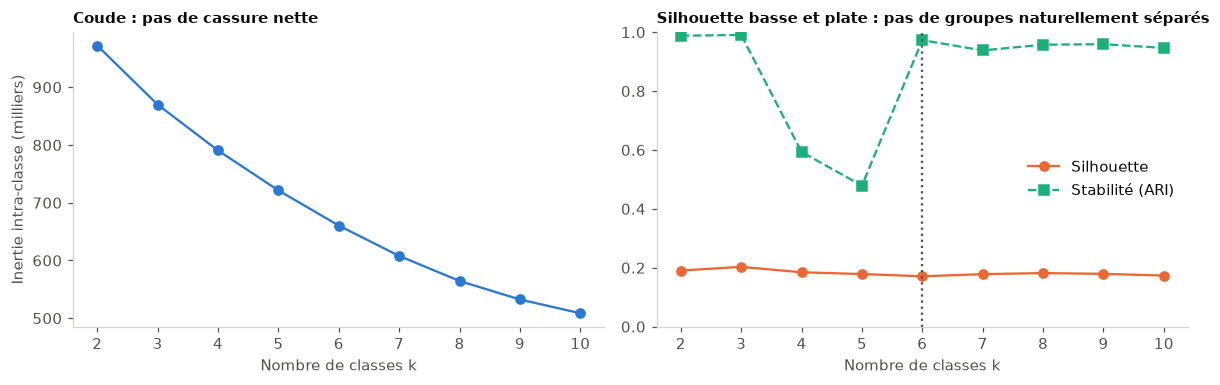

,inertie,silhouette,stabilité (ARI),plus petite classe (%)
k,,,,
2,972127.243,0.191,0.988,43.277
3,869911.253,0.203,0.991,15.347
4,790452.880,0.185,0.593,13.099
5,721353.108,0.179,0.479,11.018
6,660439.890,0.171,0.973,9.620
7,607877.110,0.178,0.938,6.573
8,564519.045,0.182,0.957,5.689
9,532436.034,0.179,0.959,1.224
10,508619.078,0.173,0.946,1.224


**Lecture honnête** : la silhouette plafonne à 0,20 (k = 3) et reste entre 0,17 et 0,20 pour tous les k : les clients forment un **continuum**, pas des îlots nets. Le clustering découpe ce continuum de façon utile, il ne « découvre » pas des groupes évidents. Le coude n'est pas marqué. On choisit donc **k = 6** par le critère du cours « interprétabilité et actionnabilité » : la silhouette de k = 6 (0,17) est proche du meilleur, la stabilité entre moitiés est de 0,97, aucune classe n'est minuscule (plus petite : 9,6 %) et chaque classe a un profil lisible (voir plus bas).

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
P = PCA(n_components=n_axes, random_state=c.SEED).fit_transform(S)
rng = np.random.RandomState(c.SEED)
samples = [rng.choice(len(P), 10000, replace=False) for _ in range(3)]
half = rng.permutation(len(P)); hA, hB = half[:len(P) // 2], half[len(P) // 2:]
res = []
for k in range(2, 11):
    km = KMeans(k, n_init=5, random_state=c.SEED).fit(P)
    sil = np.mean([silhouette_score(P[i], km.labels_[i]) for i in samples])
    la = KMeans(k, n_init=10, random_state=c.SEED).fit(P[hA]).predict(P)
    lb = KMeans(k, n_init=10, random_state=c.SEED).fit(P[hB]).predict(P)
    res.append({'k': k, 'inertie': km.inertia_, 'silhouette': sil, 'stabilité (ARI)': adjusted_rand_score(la, lb), 'plus petite classe (%)': 100 * np.bincount(km.labels_).min() / len(P)})
kres = pd.DataFrame(res).set_index('k')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(kres.index, kres['inertie'] / 1e3, 'o-', color=c.BLUE); axes[0].set_ylabel('Inertie intra-classe (milliers)'); axes[0].set_xlabel('Nombre de classes k')
axes[0].set_title("Coude : pas de cassure nette", fontsize=10, loc='left')
axes[1].plot(kres.index, kres['silhouette'], 'o-', color=c.ACCENT, label='Silhouette')
axes[1].plot(kres.index, kres['stabilité (ARI)'], 's--', color=c.GREEN, label='Stabilité (ARI)')
axes[1].axvline(6, color=c.INK2, ls=':'); axes[1].set_xlabel('Nombre de classes k'); axes[1].legend(frameon=False); axes[1].set_ylim(0, 1)
axes[1].set_title("Silhouette basse et plate : pas de groupes naturellement séparés", fontsize=10, loc='left')
fig.tight_layout(); savefig(fig, '05_coude_silhouette')
display(kres.round(3))
kbest = int(kres['silhouette'].idxmax())
say(f"**Lecture honnête** : la silhouette plafonne à {kres['silhouette'].max():.2f} (k = {kbest}) et reste entre {kres['silhouette'].min():.2f} et {kres['silhouette'].max():.2f} pour tous les k : "
    f"les clients forment un **continuum**, pas des îlots nets. Le clustering découpe ce continuum de façon utile, il ne « découvre » pas des groupes évidents. Le coude n'est pas marqué. "
    f"On choisit donc **k = 6** par le critère du cours « interprétabilité et actionnabilité » : la silhouette de k = 6 ({kres.loc[6, 'silhouette']:.2f}) est proche du meilleur, la stabilité entre moitiés est de {kres.loc[6, 'stabilité (ARI)']:.2f}, "
    f"aucune classe n'est minuscule (plus petite : {pc(kres.loc[6, 'plus petite classe (%)'])}) et chaque classe a un profil lisible (voir plus bas).")

### 3.3 CAH de Ward (slides 43-44)
La CAH exige la matrice de toutes les distances entre clients (mémoire en n², impraticable sur 160 000 clients : le cours le signale). On l'applique donc à un **échantillon aléatoire de 6 000 clients** (coordonnées factorielles), on lit le dendrogramme pour le nombre de classes et on compare à K-Means.

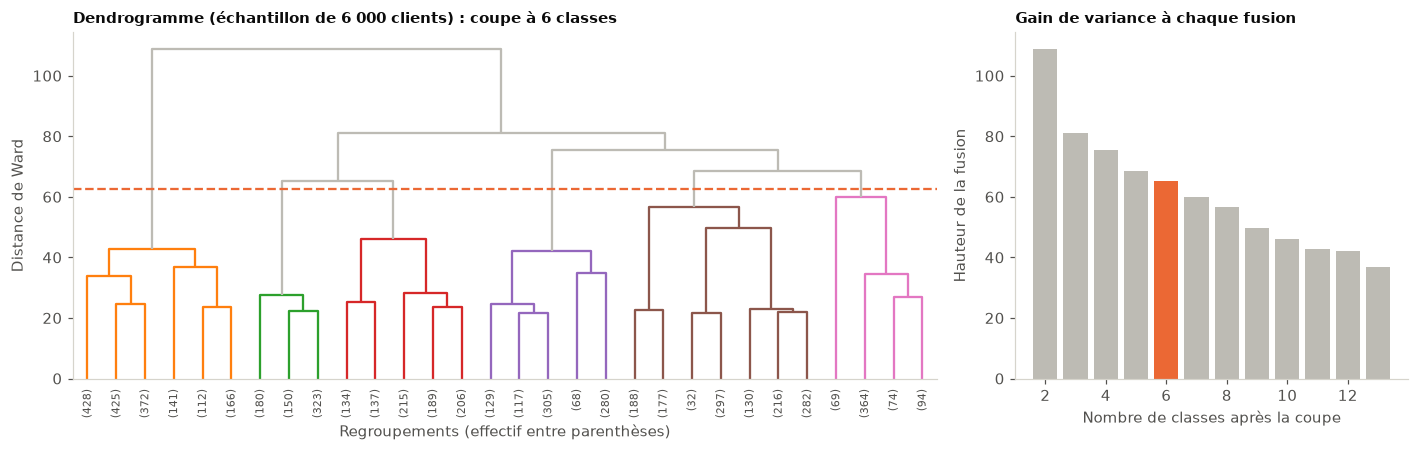

K-Means (classes),0,1,2,3,4,5
CAH (classes),,,,,,
1,1153,8,323,13,144,3
2,1,52,568,9,22,1
3,171,55,156,0,101,398
4,39,34,13,503,184,126
5,108,449,42,10,690,23
6,8,313,78,64,52,86


**Lecture** : la hauteur des fusions décroît régulièrement : aucune coupure ne s'impose nettement (même constat que la silhouette). Coupée à 6 classes, la CAH et K-Means s'accordent à **ARI = 0,34** sur l'échantillon (1 = identiques) : l'accord est modéré : les deux méthodes retrouvent les mêmes grandes familles (clients très actifs, occasionnels distingués par moment de courses ou par panier) mais pas les mêmes frontières, ce qui confirme l'absence de structure unique. Pour la suite on garde **K-Means** (il s'applique tel quel à tous les clients et au test via `segments.assign_clusters`), la CAH servant de contrôle.

In [17]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
K = 6
idx_s = np.random.RandomState(c.SEED).choice(len(P), 6000, replace=False)
Zl = linkage(P[idx_s], method='ward')
thr = (Zl[-K, 2] + Zl[-(K - 1), 2]) / 2
cah = fcluster(Zl, K, 'maxclust')
km6 = KMeans(K, n_init=10, random_state=c.SEED).fit(P)
ari = adjusted_rand_score(cah, km6.labels_[idx_s])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [2.2, 1]})
dendrogram(Zl, truncate_mode='lastp', p=30, color_threshold=thr, above_threshold_color=c.GREY, leaf_rotation=90, leaf_font_size=7, ax=axes[0])
axes[0].axhline(thr, color=c.ACCENT, ls='--'); axes[0].set_ylabel('Distance de Ward'); axes[0].set_xlabel('Regroupements (effectif entre parenthèses)')
axes[0].set_title(f"Dendrogramme (échantillon de 6 000 clients) : coupe à {K} classes", fontsize=10, loc='left')
h = Zl[-12:, 2][::-1]
axes[1].bar(range(2, 14), h, color=[c.ACCENT if k_ == K else c.GREY for k_ in range(2, 14)])
axes[1].set_xlabel('Nombre de classes après la coupe'); axes[1].set_ylabel('Hauteur de la fusion'); axes[1].set_title('Gain de variance à chaque fusion', fontsize=10, loc='left')
fig.tight_layout(); savefig(fig, '05_dendrogramme')
tab = pd.crosstab(pd.Series(cah, name='CAH (classes)'), pd.Series(km6.labels_[idx_s], name='K-Means (classes)'))
display(tab)
say(f"**Lecture** : la hauteur des fusions décroît régulièrement : aucune coupure ne s'impose nettement (même constat que la silhouette). "
    f"Coupée à {K} classes, la CAH et K-Means s'accordent à **ARI = {ari:.2f}** sur l'échantillon (1 = identiques) : l'accord est {'élevé' if ari > .6 else 'modéré'} : les deux méthodes retrouvent les mêmes grandes familles (clients très actifs, occasionnels distingués par moment de courses ou par panier) mais pas les mêmes frontières, ce qui confirme l'absence de structure unique. "
    f"Pour la suite on garde **K-Means** (il s'applique tel quel à tous les clients et au test via `segments.assign_clusters`), la CAH servant de contrôle.")

### 3.4 Profil des classes (slide 45 : on interprète avec les moyennes, puis on ajoute les variables non utilisées)
Classes numérotées par taille décroissante ; leur nom est attribué par règle sur les moyennes du train (`segments.cluster_names`).

In [18]:
model = sg.fit_clusters(Xtr, K, variance=0.80, seed=c.SEED)
cl_tr, cl_te = sg.assign_clusters(Xtr, model), sg.assign_clusters(Xte, model)
cnames = sg.cluster_names(Xtr, cl_tr)
CL_ORDER = [cnames[i] for i in sorted(cnames)]
cl_tr_n, cl_te_n = cl_tr.map(cnames), cl_te.map(cnames)
prof_cl = profile(Xtr, y, cl_tr_n, CL_ORDER, Xte, cl_te_n)
extra = Xtr.assign(_cl=cl_tr_n.values).groupby('_cl')[['recency_days', 'n_tickets_all', 'spend_all', 'trend_freq_90', 'share_weekend', 'share_evening', 'n_stores']].agg('mean').reindex(CL_ORDER)
extra['trend_freq_90'] = extra['trend_freq_90'].round(2)
display(pd.concat([show(prof_cl, ['n_clients', 'pct_clients', 'pct_ca', 'basket_mean', 'discount_rate_pct', 'pct_email', 'pct_card']),
                   extra.rename(columns={'recency_days': 'Récence moy. (j)', 'n_tickets_all': 'Tickets / an', 'spend_all': 'CA moy. (€)', 'trend_freq_90': 'Tendance fréq.', 'share_weekend': 'Part week-end', 'share_evening': 'Part soirée', 'n_stores': 'Magasins'}).round(2)], axis=1))
show(prof_cl, ['rebuy_pct', 'rebuy_ci_low', 'rebuy_ci_high', 'lift', 'rebuys', 'pct_rebuys', 'price_segment_top', 'price_segment_known_pct', 'n_clients_test', 'pct_clients_test', 'rebuys_expected_test'])

,Clients,% clients,% CA,Panier moyen (€),Remise (%),% avec e-mail,% carte fidélité,Récence moy. (j),Tickets / an,CA moy. (€),Tendance fréq.,Part week-end,Part soirée,Magasins
C1 Réguliers,38901,24.2,65.8,47.3,6.0,64.2,6.5,16.42,54.83,2593.00,-0.11,0.27,0.20,2.30
C2 Petits paniers,32090,20.0,4.5,22.8,2.0,47.1,1.1,161.97,9.46,215.60,-0.41,0.14,0.09,1.23
C3 Montants,31927,19.9,17.0,49.1,3.5,54.4,2.6,15.83,16.63,816.77,0.89,0.23,0.16,1.30
C4 Paniers premium,25194,15.7,7.2,83.1,5.4,50.7,3.0,167.90,5.28,438.82,-0.19,0.11,0.08,1.14
C5 Soirée,16880,10.5,2.4,44.5,3.8,56.3,1.4,173.05,4.96,220.52,-0.05,0.24,0.80,1.23
C6 Week-end,15432,9.6,3.1,59.7,3.8,51.3,1.8,164.49,5.10,304.24,-0.08,0.81,0.07,1.15


,Rachat août (%),IC95 bas,IC95 haut,Lift,Rachats,% des rachats,Segment de prix dominant,% prix connu,Clients test,% clients test,Rachats attendus (test)
segment,,,,,,,,,,,
C1 Réguliers,20.16,19.77,20.57,2.61,7844,63.30,Mixte,59.69,9770,24.36,1970.02
C2 Petits paniers,1.27,1.16,1.40,0.16,409,3.30,Mixte,46.86,7877,19.64,100.40
C3 Montants,9.77,9.45,10.10,1.26,3118,25.16,Mixte,42.88,8000,19.95,781.28
C4 Paniers premium,1.10,0.98,1.24,0.14,278,2.24,Mixte,25.03,6403,15.97,70.65
C5 Soirée,1.65,1.47,1.85,0.21,278,2.24,Mixte,34.74,4195,10.46,69.09
C6 Week-end,3.01,2.75,3.29,0.39,465,3.75,Mixte,34.13,3861,9.63,116.34


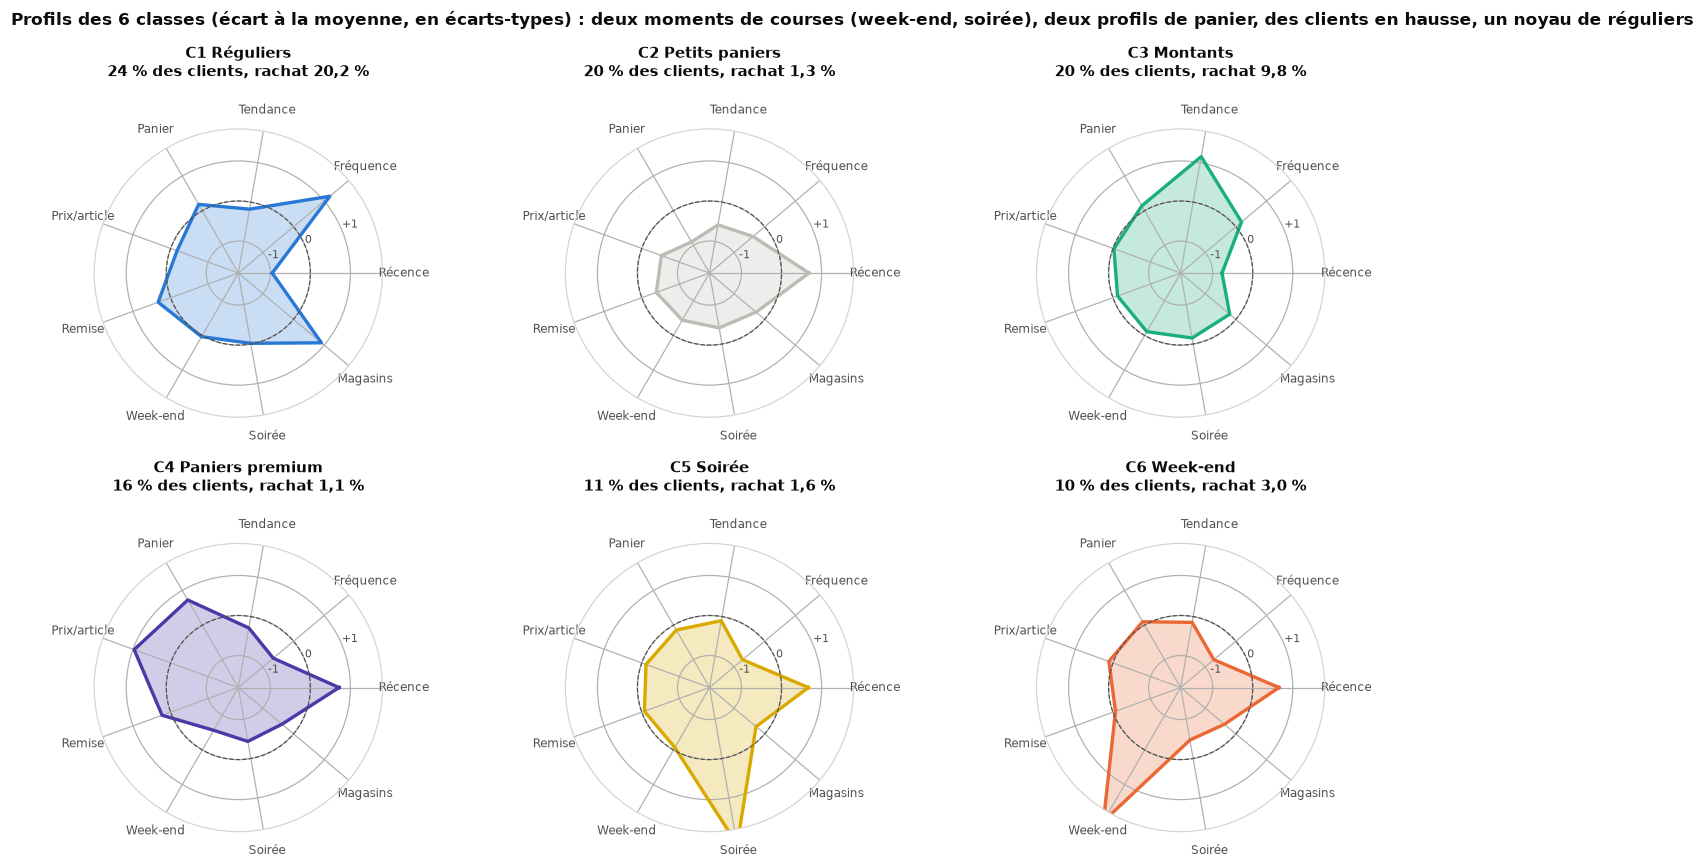

In [19]:
Zc = sg.cluster_matrix(Xtr)
zc = ((Zc.groupby(cl_tr_n.values).mean().reindex(CL_ORDER) - Zc.mean()) / Zc.std())
labs = [short[v] for v in Zc.columns]
ang = np.r_[np.linspace(0, 2 * np.pi, len(labs), endpoint=False), 0]
pal = [c.BLUE, c.GREY, c.GREEN, c.PURPLE, '#d9a900', c.ACCENT]
fig, axes = plt.subplots(2, 3, figsize=(13, 8), subplot_kw={'projection': 'polar'})
for ax, (nm_, row), col in zip(axes.ravel(), zc.iterrows(), pal):
    v = np.r_[row.values, row.values[0]]
    ax.plot(ang, v, color=col, lw=2.2); ax.fill(ang, v, color=col, alpha=.25)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(labs, fontsize=8); ax.set_ylim(-1.8, 1.8); ax.set_yticks([-1, 0, 1]); ax.set_yticklabels(['-1', '0', '+1'], fontsize=7)
    ax.plot(np.linspace(0, 2 * np.pi, 100), np.zeros(100), color=c.INK2, lw=.8, ls='--')
    ax.set_title(f"{nm_}\n{pc(prof_cl.loc[nm_, 'pct_clients'], 0)} des clients, rachat {pc(prof_cl.loc[nm_, 'rebuy_pct'])}", fontsize=10, pad=18)
fig.suptitle("Profils des 6 classes (écart à la moyenne, en écarts-types) : deux moments de courses (week-end, soirée), deux profils de panier, des clients en hausse, un noyau de réguliers", x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout(); savefig(fig, '05_radar_classes')

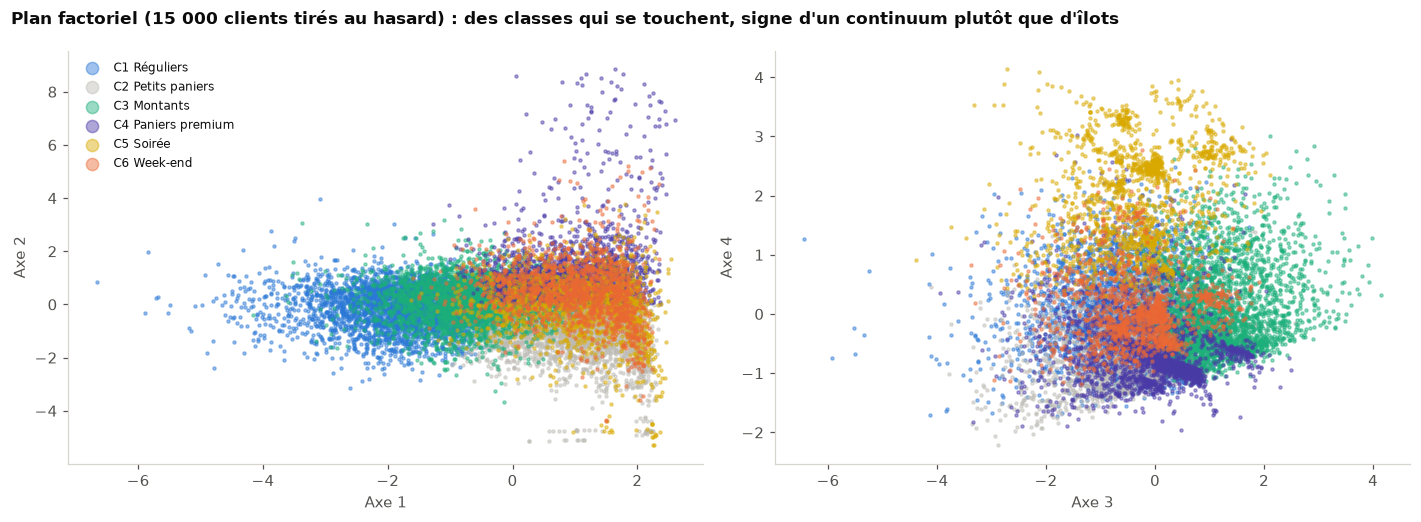

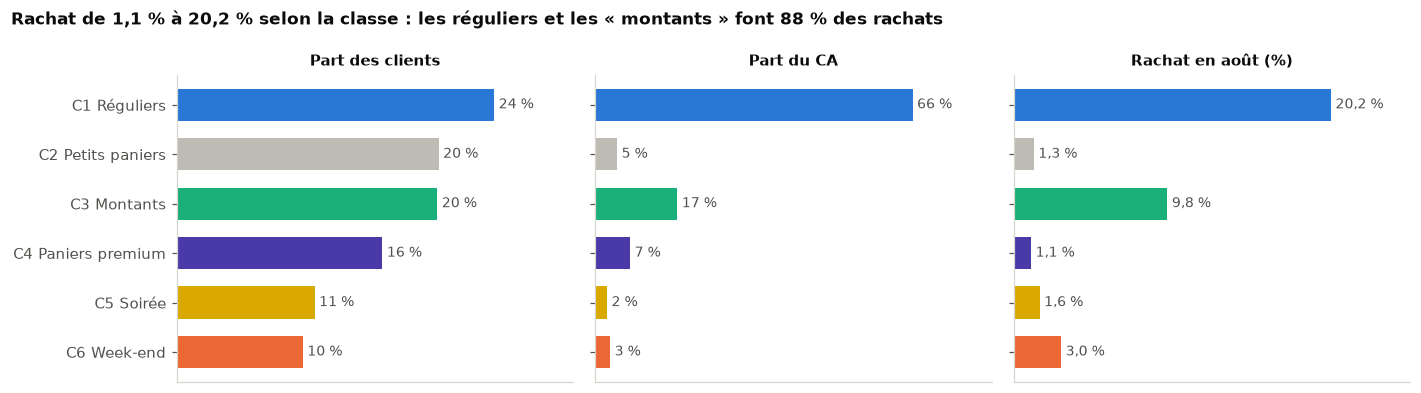

In [20]:
rs = np.random.RandomState(c.SEED).choice(len(P), 15000, replace=False)
Pf = PCA(n_components=n_axes, random_state=c.SEED).fit(S).transform(S)
lab_s = cl_tr_n.values[rs]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    for nm_, col in zip(CL_ORDER, pal):
        m = lab_s == nm_
        ax.scatter(Pf[rs][m, a], Pf[rs][m, b], s=4, alpha=.45, color=col, label=nm_)
    ax.set_xlabel(f"Axe {a+1}"); ax.set_ylabel(f"Axe {b+1}")
axes[0].legend(markerscale=4, frameon=False, fontsize=8, loc='best')
fig.suptitle("Plan factoriel (15 000 clients tirés au hasard) : des classes qui se touchent, signe d'un continuum plutôt que d'îlots", x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout(); savefig(fig, '05_plan_factoriel')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, col, ttl in zip(axes, ['pct_clients', 'pct_ca', 'rebuy_pct'], ['Part des clients', "Part du CA", "Rachat en août (%)"]):
    b = ax.barh(CL_ORDER, prof_cl[col], color=pal, height=.65)
    ax.bar_label(b, labels=[pc(v, 0 if col != 'rebuy_pct' else 1) for v in prof_cl[col]], padding=3, fontsize=9, color=c.INK2)
    ax.set_title(ttl, fontsize=10); ax.set_xlim(0, prof_cl[col].max() * 1.25); ax.set_xticks([])
axes[0].invert_yaxis()
fig.suptitle(f"Rachat de {pc(prof_cl['rebuy_pct'].min())} à {pc(prof_cl['rebuy_pct'].max())} selon la classe : les réguliers et les « montants » font {pc(prof_cl['pct_rebuys'].iloc[[0, 2]].sum(), 0)} des rachats", x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout(); savefig(fig, '05_classes_poids_rachat')

In [21]:
CLN = {k.split(' ', 1)[1]: k for k in CL_ORDER}
def L(n): return prof_cl.loc[CLN[n]]
say(f"**Lecture marketing** (les chiffres viennent du tableau ci-dessus) :\n"
    f"- **{CLN['Réguliers']}** : {pc(L('Réguliers').pct_clients, 0)} des clients, {pc(L('Réguliers').pct_ca, 0)} du CA, {L('Réguliers').tickets_per_client:.0f} tickets par an, {pc(L('Réguliers').rebuy_pct)} de rachat : le noyau dur, déjà acquis.\n"
    f"- **{CLN['Montants']}** : fréquence en hausse sur les 90 derniers jours, récents, {L('Montants').tickets_per_client:.0f} tickets par an ; rachat {pc(L('Montants').rebuy_pct)}, {pc(L('Montants').pct_rebuys, 0)} des rachats : les clients en train de devenir réguliers.\n"
    f"- **{CLN['Week-end']}** et **{CLN['Soirée']}** : clients occasionnels définis par leur *moment* de courses (en moyenne {pc(100*extra.loc[CLN['Week-end'], 'share_weekend'], 0)} de leurs tickets le week-end, ou {pc(100*extra.loc[CLN['Soirée'], 'share_evening'], 0)} en soirée), rachat {pc(L('Week-end').rebuy_pct)} et {pc(L('Soirée').rebuy_pct)} : une distinction que le RFM ne fait pas.\n"
    f"- **{CLN['Paniers premium']}** : peu de passages mais un panier moyen de {L('Paniers premium').basket_mean:.0f} € (contre {fr(prof_cl['basket_mean'].drop(CLN['Paniers premium']).min())} à {fr(prof_cl['basket_mean'].drop(CLN['Paniers premium']).max())} € pour les autres classes), prix par article élevé ; rachat {pc(L('Paniers premium').rebuy_pct)}.\n"
    f"- **{CLN['Petits paniers']}** : paniers de {L('Petits paniers').basket_mean:.0f} € en moyenne, fréquence en baisse, rachat {pc(L('Petits paniers').rebuy_pct)} : des clients de dépannage qui s'éloignent.")

**Lecture marketing** (les chiffres viennent du tableau ci-dessus) :
- **C1 Réguliers** : 24 % des clients, 66 % du CA, 55 tickets par an, 20,2 % de rachat : le noyau dur, déjà acquis.
- **C3 Montants** : fréquence en hausse sur les 90 derniers jours, récents, 17 tickets par an ; rachat 9,8 %, 25 % des rachats : les clients en train de devenir réguliers.
- **C6 Week-end** et **C5 Soirée** : clients occasionnels définis par leur *moment* de courses (en moyenne 81 % de leurs tickets le week-end, ou 80 % en soirée), rachat 3,0 % et 1,6 % : une distinction que le RFM ne fait pas.
- **C4 Paniers premium** : peu de passages mais un panier moyen de 83 € (contre 23 à 60 € pour les autres classes), prix par article élevé ; rachat 1,1 %.
- **C2 Petits paniers** : paniers de 23 € en moyenne, fréquence en baisse, rachat 1,3 % : des clients de dépannage qui s'éloignent.

### 3.5 Modèle de réaffectation (slide 47)
Pour classer **un nouveau client** dans une classe sans refaire tourner K-Means (ni l'ACP), on entraîne un modèle supervisé qui prédit la classe à partir des variables brutes. On compare un **arbre de décision peu profond** (règles lisibles) à une **régression logistique** multinomiale, en validation croisée sur les 5 plis communs du projet (les classes viennent de K-Means ajusté sur tout le train : l'évaluation mesure la fidélité de la réplique, pas une performance prédictive sur le rachat).

In [22]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix
TV = ['recency_days', 'n_tickets_all', 'trend_freq_90', 'basket_mean_all', 'price_per_item_mean', 'discount_rate_all', 'share_weekend', 'share_evening', 'n_stores']
Xr = Xtr[TV].fillna(Xtr[TV].median())
yc = cl_tr_n
def cv_pred(make):
    pred = pd.Series(index=Xr.index, dtype=object)
    for k_ in range(c.N_FOLDS):
        tr_, va_ = (folds != k_).values, (folds == k_).values
        pred[va_] = make().fit(Xr[tr_], yc[tr_]).predict(Xr[va_])
    return pred
rows = []
for d_ in [2, 3, 4, 5, 6]:
    p_ = cv_pred(lambda d_=d_: DecisionTreeClassifier(max_depth=d_, min_samples_leaf=300, random_state=c.SEED))
    rows.append({'modèle': f'Arbre, profondeur {d_}', 'exactitude (CV)': (p_ == yc).mean(), 'feuilles': 2 ** d_})
p_lr = cv_pred(lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, C=1.0)))
rows.append({'modèle': 'Régression logistique multinomiale (brutes)', 'exactitude (CV)': (p_lr == yc).mean(), 'feuilles': np.nan})
acc = pd.DataFrame(rows).set_index('modèle').round(3)
display(acc)

,exactitude (CV),feuilles
modèle,,
"Arbre, profondeur 2",0.575,4.0
"Arbre, profondeur 3",0.656,8.0
"Arbre, profondeur 4",0.760,16.0
"Arbre, profondeur 5",0.792,32.0
"Arbre, profondeur 6",0.817,64.0
Régression logistique multinomiale (brutes),0.936,NaN


,C1 Réguliers,C2 Petits paniers,C3 Montants,C4 Paniers premium,C5 Soirée,C6 Week-end
classe réelle (lignes) / prédite (colonnes),,,,,,
C1 Réguliers,78,4,11,5,1,1
C2 Petits paniers,4,69,9,11,3,4
C3 Montants,8,5,79,5,1,1
C4 Paniers premium,1,17,10,66,4,3
C5 Soirée,2,1,7,2,88,0
C6 Week-end,3,0,13,1,1,82


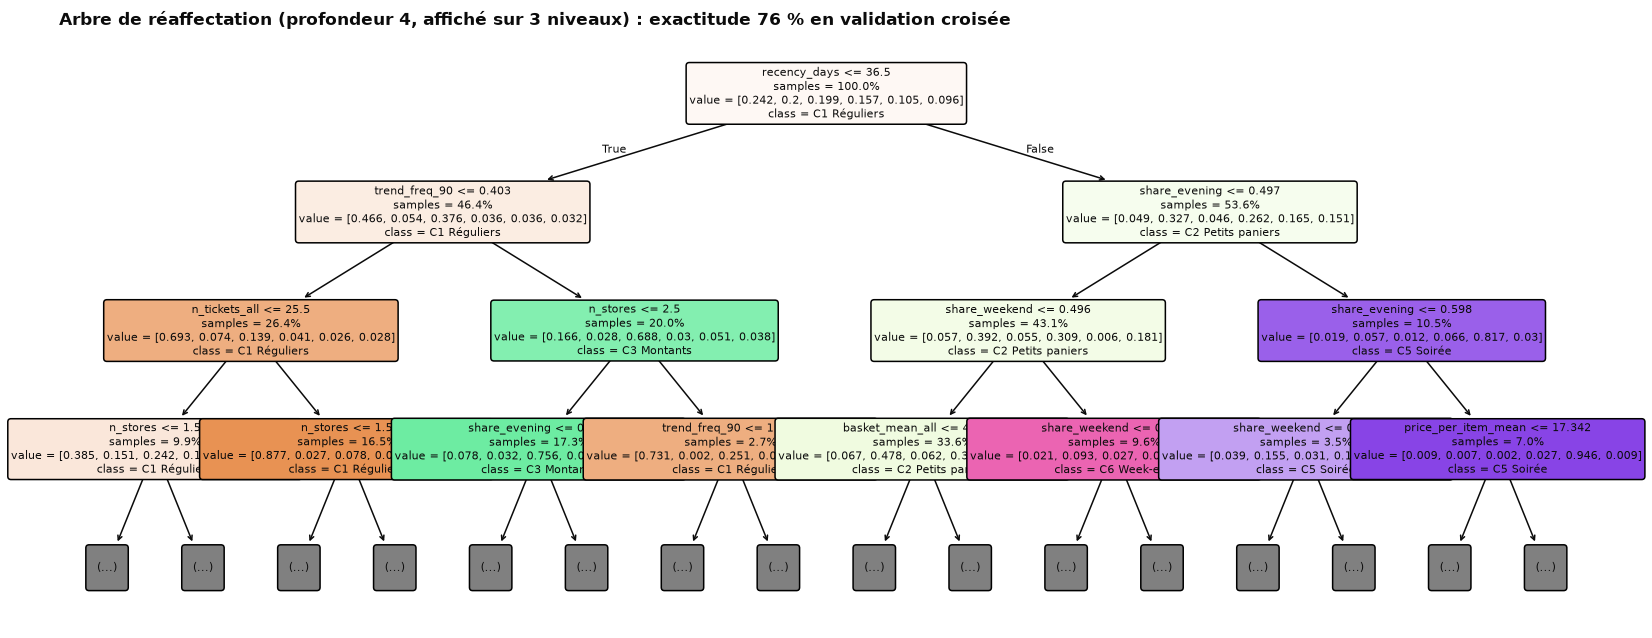

|--- recency_days <= 36.5
|   |--- trend_freq_90 <= 0.4
|   |   |--- n_tickets_all <= 25.5
|   |   |   |--- n_stores <= 1.5
|   |   |   |   |--- class: C3 Montants
|   |   |   |--- n_stores >  1.5
|   |   |   |   |--- class: C1 Réguliers
|   |   |--- n_tickets_all >  25.5
|   |   |   |--- n_stores <= 1.5
|   |   |   |   |--- class: C1 Réguliers
|   |   |   |--- n_stores >  1.5
|   |   |   |   |--- class: C1 Réguliers
|   |--- trend_freq_90 >  0.4
|   |   |--- n_stores <= 2.5
|   |   |   |--- share_evening <= 0.7
|   |   |   |   |--- class: C3 Montants
|   |   |   |--- share_evening >  0.7
|   |   |   |   |--- class: C5 Soirée
|   |   |--- n_stores >  2.5
|   |   |   |--- trend_freq_90 <= 1.1
|   |   |   |   |--- class: C1 Réguliers
|   |   |   |--- trend_freq_90 >  1.1
|   |   |   |   |--- class: C3 Montants
|--- recency_days >  36.5
|   |--- share_evening <= 0.5
|   |   |--- share_weekend <= 0.5
|   |   |   |--- basket_mean_all <= 40.9
|   |   |   |   |--- class: C2 Petits paniers
|  

In [23]:
DEPTH = 4
tree = DecisionTreeClassifier(max_depth=DEPTH, min_samples_leaf=300, random_state=c.SEED).fit(Xr, yc)
p_tree = cv_pred(lambda: DecisionTreeClassifier(max_depth=DEPTH, min_samples_leaf=300, random_state=c.SEED))
cm_ = pd.DataFrame(confusion_matrix(yc, p_tree, labels=CL_ORDER, normalize='true'), index=CL_ORDER, columns=CL_ORDER)
display((100 * cm_).round(0).astype(int).rename_axis('classe réelle (lignes) / prédite (colonnes)'))
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(tree, feature_names=TV, class_names=list(tree.classes_), filled=True, impurity=False, proportion=True, fontsize=7, max_depth=3, ax=ax, rounded=True)
ax.set_title(f"Arbre de réaffectation (profondeur {DEPTH}, affiché sur 3 niveaux) : exactitude {100*(p_tree == yc).mean():.0f} % en validation croisée".replace('.', ','), loc='left', fontsize=11)
savefig(fig, '05_arbre_reallocation')
print(export_text(tree, feature_names=TV, max_depth=3, decimals=1)[:3500])

In [24]:
Xr_te = Xte[TV].fillna(Xtr[TV].median())
p_te = pd.Series(tree.predict(Xr_te), index=Xte.index)
agree_te = (p_te == cl_te_n).mean()
a_tree = (p_tree == yc).mean()
worst = (100 * pd.Series(np.diag(cm_), index=CL_ORDER)).idxmin()
p_lr_te = pd.Series(make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)).fit(Xr, yc).predict(Xr_te), index=Xte.index)
agree_lr_te = (p_lr_te == cl_te_n).mean()
a_lr = (p_lr == yc).mean()
say(f"**Lecture** : l'arbre de profondeur {DEPTH} (lisible, {tree.get_n_leaves()} feuilles) retrouve la classe K-Means de **{pc(100*a_tree, 0)}** des clients en validation croisée ; la régression logistique, de **{pc(100*a_lr, 0)}** (accord avec K-Means sur le test : {pc(100*agree_lr_te, 0)} contre {pc(100*agree_te, 0)} pour l'arbre). "
    f"Les classes viennent d'un K-Means sur des axes qui combinent toutes les variables, ce qu'un arbre peu profond, qui coupe une variable à la fois, reproduit mal ; la logistique, linéaire, s'en approche bien mieux. "
    f"La classe la moins bien reproduite par l'arbre est **{worst}** ({pc(100*cm_.loc[worst, worst], 0)} de bien classés). "
    f"Compromis du cours (performance / interprétabilité) : **la logistique pour affecter automatiquement** de nouveaux clients, **l'arbre pour lire les règles** : la première coupure est la récence ({tree.tree_.threshold[0]:.0f} jours), puis la tendance de fréquence et le nombre de tickets chez les clients récents, la part de soirée ou de week-end et le panier chez les absents.")

**Lecture** : l'arbre de profondeur 4 (lisible, 16 feuilles) retrouve la classe K-Means de **76 %** des clients en validation croisée ; la régression logistique, de **94 %** (accord avec K-Means sur le test : 94 % contre 76 % pour l'arbre). Les classes viennent d'un K-Means sur des axes qui combinent toutes les variables, ce qu'un arbre peu profond, qui coupe une variable à la fois, reproduit mal ; la logistique, linéaire, s'en approche bien mieux. La classe la moins bien reproduite par l'arbre est **C4 Paniers premium** (66 % de bien classés). Compromis du cours (performance / interprétabilité) : **la logistique pour affecter automatiquement** de nouveaux clients, **l'arbre pour lire les règles** : la première coupure est la récence (36 jours), puis la tendance de fréquence et le nombre de tickets chez les clients récents, la part de soirée ou de week-end et le panier chez les absents.

### 3.6 RFM et clustering : se contredisent-ils ou se complètent-ils ?
On croise les deux segmentations, puis on mesure leur **pouvoir discriminant** sur le rachat : chaque segmentation sert de score (taux de rachat moyen du groupe, estimé hors-pli sur les 4 autres plis communs du projet, lissé vers la moyenne), et on calcule l'AUC. C'est un **instrument de mesure** de la segmentation, pas une variable de modèle : rien n'est réutilisé ailleurs.

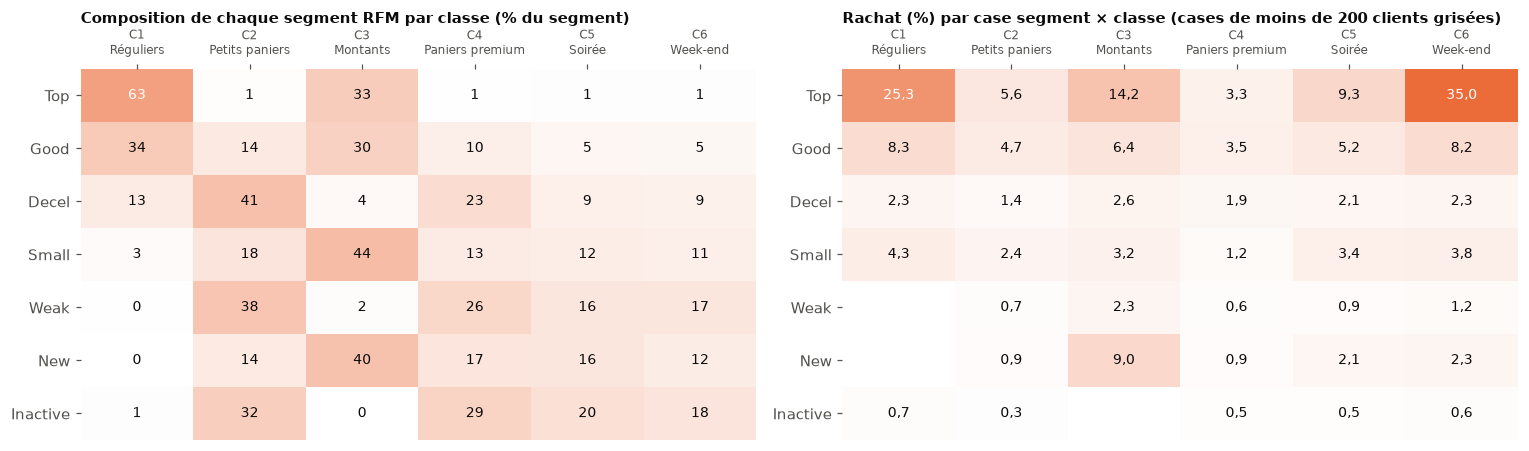

,AUC sur le rachat
"Récence seule (règle, sans estimation)",0.818
RFM : 7 segments,0.807
RFM : 9 cases + New + Inactive,0.825
Clustering : 6 classes,0.781
RFM 7 segments × classes,0.829


In [25]:
ct = pd.crosstab(seg_tr, cl_tr_n).reindex(index=ORDER, columns=CL_ORDER)
comp = 100 * ct.div(ct.sum(axis=1), axis=0)
cell_rate = (100 * y.groupby([seg_tr, cl_tr_n]).mean().unstack().reindex(index=ORDER, columns=CL_ORDER)).where(ct >= 200)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, M_, ttl, vmax, fmt in [(axes[0], comp, "Composition de chaque segment RFM par classe (% du segment)", 100, '{:.0f}'), (axes[1], cell_rate, "Rachat (%) par case segment × classe (cases de moins de 200 clients grisées)", 36, '{:.1f}')]:
    ax.imshow(np.nan_to_num(M_.values, nan=-1), cmap=LinearSegmentedColormap.from_list('w', ['#ffffff', c.ACCENT]), vmin=0, vmax=vmax, aspect='auto')
    for i in range(M_.shape[0]):
        for j in range(M_.shape[1]):
            v = M_.iloc[i, j]
            if not np.isnan(v): ax.text(j, i, fmt.format(v).replace('.', ','), ha='center', va='center', fontsize=9, color='white' if v > .6 * vmax else c.INK)
    ax.set_xticks(range(len(CL_ORDER))); ax.set_xticklabels([n.replace(' ', '\n', 1) for n in CL_ORDER], fontsize=8); ax.set_yticks(range(len(ORDER))); ax.set_yticklabels(ORDER)
    ax.xaxis.tick_top(); ax.spines[:].set_visible(False); ax.set_title(ttl, fontsize=10, loc='left', pad=30)
fig.tight_layout(); savefig(fig, '05_rfm_vs_classes')

from sklearn.metrics import roc_auc_score
def cv_group_auc(groups, prior=20):
    oof = pd.Series(index=y.index, dtype=float)
    for k_ in range(c.N_FOLDS):
        trm = (folds != k_).values
        st = y[trm].groupby(groups[trm]).agg(['sum', 'count'])
        rate = (st['sum'] + prior * base) / (st['count'] + prior)
        oof[~trm] = groups[~trm].map(rate).fillna(base).values
    return roc_auc_score(y, oof)
cell_tr = sg.rfm_cell(Xtr)
auc_rows = {'Récence seule (règle, sans estimation)': roc_auc_score(y[Xtr['recency_days'].notna()], -Xtr['recency_days'].dropna()),
            f"RFM : 7 segments": cv_group_auc(seg_tr.astype(str)),
            "RFM : 9 cases + New + Inactive": cv_group_auc(cell_tr.astype(str)),
            f"Clustering : {K} classes": cv_group_auc(cl_tr_n.astype(str)),
            "RFM 7 segments × classes": cv_group_auc(seg_tr.astype(str) + '|' + cl_tr_n.astype(str))}
auc_tab = pd.Series(auc_rows, name='AUC sur le rachat').round(3).to_frame()
display(auc_tab)

In [26]:
wk = cell_rate.loc['Top']
say(f"**Ce que le clustering révèle** :\n"
    f"- Dans le segment Top, le taux de rachat varie de {pc(wk.min())} à {pc(wk.max())} selon la classe : le RFM met dans le même sac des réguliers très stables et des clients dont le rythme est plus faible ou plus irrégulier. "
    f"Les 7 segments RFM atteignent une AUC de {auc_tab.iloc[1, 0]:.3f}, les {K} classes {auc_tab.iloc[3, 0]:.3f}, et leur croisement {auc_tab.iloc[4, 0]:.3f}, contre {auc_tab.iloc[0, 0]:.3f} pour la récence seule : "
    f"le RFM ne fait pas mieux que la récence brute, et le clustering n'ajoute qu'une touche de plus. Segments et classes servent à **cibler et parler aux clients**, pas à remplacer le modèle de score.\n"
    f"- Le clustering distingue des clients **inactifs ou occasionnels** selon l'heure et le jour de courses (week-end, soirée) et la gamme (paniers premium) : le RFM les voit tous Small, Weak ou Inactive. Utile pour choisir le message, moins pour prédire le rachat.\n"
    f"- Dans le segment Good, les rachats vont de {pc(cell_rate.loc['Good'].min())} à {pc(cell_rate.loc['Good'].max())} selon la classe : il existe un sous-groupe plus chaud dans ce segment, que le score du notebook 07 devra départager.")

**Ce que le clustering révèle** :
- Dans le segment Top, le taux de rachat varie de 3,3 % à 35,0 % selon la classe : le RFM met dans le même sac des réguliers très stables et des clients dont le rythme est plus faible ou plus irrégulier. Les 7 segments RFM atteignent une AUC de 0,807, les 6 classes 0,781, et leur croisement 0,829, contre 0,818 pour la récence seule : le RFM ne fait pas mieux que la récence brute, et le clustering n'ajoute qu'une touche de plus. Segments et classes servent à **cibler et parler aux clients**, pas à remplacer le modèle de score.
- Le clustering distingue des clients **inactifs ou occasionnels** selon l'heure et le jour de courses (week-end, soirée) et la gamme (paniers premium) : le RFM les voit tous Small, Weak ou Inactive. Utile pour choisir le message, moins pour prédire le rachat.
- Dans le segment Good, les rachats vont de 3,5 % à 8,3 % selon la classe : il existe un sous-groupe plus chaud dans ce segment, que le score du notebook 07 devra départager.

## 4. Candidats pour le segment cible

**Lien avec le cours** : slides 74-76 (ciblage, test A/B avec groupe témoin) et Projet 1 (choix de « Decel » sur un poids, un profil et un levier chiffré ; « récompenses sans remise » pour ne pas brader auprès de clients déjà acquis).

On évalue **tous** les segments (7 RFM + 6 classes) avec sept critères fixés *avant* de regarder qui gagne. Le but du marketing : **réveiller des clients** par un e-mail promotionnel, avec un budget limité (au plus 10 % de la base).

| # | Critère | Seuil | Pourquoi |
|---|---|---|---|
| C1 | **Taille pour un test A/B** | effet minimal détectable ≤ 25 % relatif (témoin 30 %, e-mailables, puissance 80 %) | Un test doit pouvoir détecter un effet réaliste de la campagne |
| C2 | Poids dans les rachats | ≥ 5 % des rachats d'août | Le segment doit compter pour le résultat global |
| C3 | **Pas déjà acquis** | moins de 9 mois actifs sur 12 en moyenne | Un client actif presque tous les mois achètera de toute façon : remiser serait une subvention |
| C4 | Rachat mesurable | taux ≥ 3 % | Assez d'événements pour mesurer, des clients encore dans la boucle |
| C5 | Joignabilité | % avec e-mail ≥ moyenne de la base | Le canal de la campagne est l'e-mail |
| C6 | Valeur | CA par client ≥ moyenne de la base | Un réveil doit rapporter plus que le coût de la remise |
| C7 | Cohérence « réveil » | récence médiane entre 15 et 180 jours et tickets médians ≥ 8 | Client installé (≥ 8 tickets) mais pas venu depuis plus de deux semaines (pas perdu) |

C1 et C3 sont **éliminatoires**. Le **test A/B** suppose 30 % de clients en groupe témoin (comme au Projet 1) ; les effectifs sont ceux de la **base disponible (train + test)** ; les taux de rachat sont ceux du train.

In [27]:
Xall = pd.concat([Xtr, Xte])
seg_all, cl_all = pd.concat([seg_tr.astype(str), seg_te.astype(str)]), pd.concat([cl_tr_n, cl_te_n])
POW, CTRL = NormalIndPower(), 0.30
def mde_abs(p0, n_total, ctrl=CTRL, alpha=.05, power=.80):
    h = POW.solve_power(effect_size=None, nobs1=n_total * (1 - ctrl), alpha=alpha, power=power, ratio=ctrl / (1 - ctrl))
    return np.sin(np.arcsin(np.sqrt(p0)) + h / 2) ** 2 - p0
def n_needed(p0, rel, ctrl=CTRL, alpha=.05, power=.80):
    p1 = min(p0 * (1 + rel), .999)
    h = 2 * (np.arcsin(np.sqrt(p1)) - np.arcsin(np.sqrt(p0)))
    return POW.solve_power(effect_size=h, nobs1=None, alpha=alpha, power=power, ratio=ctrl / (1 - ctrl)) / (1 - ctrl)

allp = pd.concat([prof_rfm.assign(famille='RFM'), prof_cl.assign(famille='Classe')])
allp.index.name = 'segment'
em = pd.concat([Xall['has_email'].groupby(seg_all.values).sum(), Xall['has_email'].groupby(cl_all.values).sum()])
allp['n_email_base'] = em.reindex(allp.index)
allp['n_base'] = pd.concat([seg_all.value_counts(), cl_all.value_counts()]).reindex(allp.index)
p0 = allp['rebuy_pct'] / 100
allp['mde_abs_pts'] = [100 * mde_abs(p, n) for p, n in zip(p0, allp['n_email_base'])]
allp['mde_rel_pct'] = 100 * allp['mde_abs_pts'] / allp['rebuy_pct']
allp['n_needed_rel20'] = [n_needed(p, .20) for p in p0]
base_ca, base_em = Xtr['spend_all'].mean(), 100 * Xtr['has_email'].mean()
crit = pd.DataFrame({
    'C1 taille A/B': allp['mde_rel_pct'] <= 25, 'C2 poids rachats': allp['pct_rebuys'] >= 5, 'C3 pas acquis': allp['active_months'] < 9,
    'C4 rachat ≥ 3 %': allp['rebuy_pct'] >= 3, 'C5 e-mail': allp['pct_email'] >= base_em, 'C6 valeur': allp['ca_per_client'] >= base_ca,
    'C7 réveil': allp['recency_median'].between(15, 180) & (allp['tickets_median'] >= 8)})
allp['criteria_met'] = crit.sum(axis=1)
allp['eliminated'] = ~(crit['C1 taille A/B'] & crit['C3 pas acquis'])
ranked = allp.assign(_k=allp['criteria_met'] + 0.001 * allp['pct_rebuys']).query('not eliminated').sort_values('_k', ascending=False)
shortlist = list(ranked.index[:3])
RECO = shortlist[0]
allp['decision'] = np.where(allp.index == RECO, 'recommandé', np.where(allp.index.isin(shortlist), 'candidat', np.where(allp['eliminated'], 'éliminé (C1 ou C3)', 'écarté')))
view = crit.replace({True: '✓', False: '✗'}).join(allp[['criteria_met', 'decision']])
view.insert(0, 'e-mailables', allp['n_email_base'].map(fr)); view.insert(1, 'rachat (%)', allp['rebuy_pct'].round(1)); view.insert(2, 'effet min. détectable (rel. %)', allp['mde_rel_pct'].round(0))
display(view.sort_values('criteria_met', ascending=False))
say(f"**Résultat** : {len(shortlist)} candidats passent les critères éliminatoires avec le plus de critères satisfaits : **{', '.join(shortlist)}**. "
    f"Éliminés par C1 ou C3 : {', '.join(allp.index[allp['eliminated']])}. "
    f"Top et les Réguliers sont éliminés par C3 : ils sont actifs presque tous les mois ({allp.loc['Top', 'active_months']:.1f} mois actifs sur 12 en moyenne pour Top), le risque est de leur offrir une remise sur des achats qu'ils feraient de toute façon.")

,e-mailables,rachat (%),effet min. détectable (rel. %),C1 taille A/B,C2 poids rachats,C3 pas acquis,C4 rachat ≥ 3 %,C5 e-mail,C6 valeur,C7 réveil,criteria_met,decision
segment,,,,,,,,,,,,
Good,17 486,6.5,18.0,✓,✓,✓,✓,✓,✓,✓,7,recommandé
Top,33 837,21.2,6.0,✓,✓,✗,✓,✓,✓,✗,5,éliminé (C1 ou C3)
C1 Réguliers,31 234,20.2,7.0,✓,✓,✗,✓,✓,✓,✗,5,éliminé (C1 ou C3)
C3 Montants,21 756,9.8,13.0,✓,✓,✓,✓,✗,✗,✗,4,candidat
Decel,9 206,1.8,52.0,✗,✗,✓,✗,✓,✗,✓,3,éliminé (C1 ou C3)
New,6 766,4.6,37.0,✗,✗,✓,✓,✗,✗,✗,2,éliminé (C1 ou C3)
C5 Soirée,11 823,1.6,48.0,✗,✗,✓,✗,✓,✗,✗,2,éliminé (C1 ou C3)
C6 Week-end,9 847,3.0,38.0,✗,✗,✓,✓,✗,✗,✗,2,éliminé (C1 ou C3)
Small,7 094,2.9,46.0,✗,✗,✓,✗,✗,✗,✗,1,éliminé (C1 ou C3)


**Résultat** : 2 candidats passent les critères éliminatoires avec le plus de critères satisfaits : **Good, C3 Montants**. Éliminés par C1 ou C3 : Top, Decel, Small, Weak, New, Inactive, C1 Réguliers, C2 Petits paniers, C4 Paniers premium, C5 Soirée, C6 Week-end. Top et les Réguliers sont éliminés par C3 : ils sont actifs presque tous les mois (9,9 mois actifs sur 12 en moyenne pour Top), le risque est de leur offrir une remise sur des achats qu'ils feraient de toute façon.

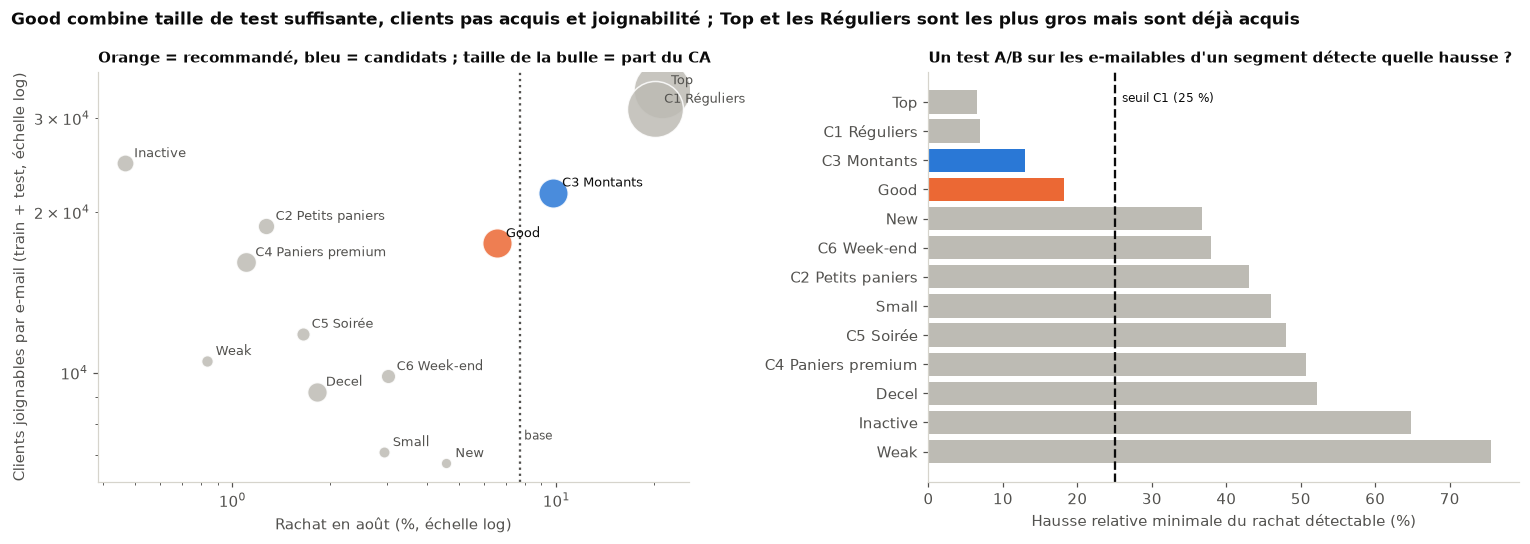

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for nm_, r in allp.iterrows():
    col = c.ACCENT if nm_ == RECO else (c.BLUE if nm_ in shortlist else c.GREY)
    ax.scatter(r['rebuy_pct'], r['n_email_base'], s=30 + 20 * r['pct_ca'], color=col, alpha=.85, edgecolor='white')
    ax.annotate(nm_, (r['rebuy_pct'], r['n_email_base']), xytext=(6, 4), textcoords='offset points', fontsize=8.5, color=c.INK if nm_ in shortlist else c.INK2)
ax.set_yscale('log'); ax.set_xscale('log'); ax.set_xlabel("Rachat en août (%, échelle log)"); ax.set_ylabel("Clients joignables par e-mail (train + test, échelle log)")
ax.axvline(100 * base, color=c.INK2, ls=':'); ax.text(100 * base * 1.03, ax.get_ylim()[0] * 1.2, 'base', fontsize=8, color=c.INK2)
ax.set_title("Orange = recommandé, bleu = candidats ; taille de la bulle = part du CA", fontsize=10, loc='left')
ax = axes[1]
order_ = allp.sort_values('mde_rel_pct').index
ax.barh(order_, allp.loc[order_, 'mde_rel_pct'], color=[c.ACCENT if n == RECO else (c.BLUE if n in shortlist else c.GREY) for n in order_])
ax.axvline(25, color=c.INK, ls='--'); ax.text(26, 0, 'seuil C1 (25 %)', fontsize=8); ax.set_xlabel("Hausse relative minimale du rachat détectable (%)")
ax.set_xlim(0, min(120, allp['mde_rel_pct'].max() * 1.05)); ax.invert_yaxis()
ax.set_title("Un test A/B sur les e-mailables d'un segment détecte quelle hausse ?", fontsize=10, loc='left')
fig.suptitle(f"{RECO} combine taille de test suffisante, clients pas acquis et joignabilité ; Top et les Réguliers sont les plus gros mais sont déjà acquis", x=0.01, ha='left', fontweight='bold', fontsize=11)
fig.tight_layout(); savefig(fig, '05_candidats')

In [29]:
cand = allp.loc[shortlist, ['n_base', 'n_email_base', 'pct_email', 'rebuy_pct', 'lift', 'pct_rebuys', 'pct_ca', 'ca_per_client', 'basket_mean', 'active_months', 'mde_abs_pts', 'mde_rel_pct', 'n_needed_rel20']]
cand['n_needed_rel20_ok'] = np.where(cand['n_needed_rel20'] <= cand['n_email_base'], 'oui', 'non')
display(cand.rename(columns={'n_base': 'Clients (base)', 'n_email_base': 'Joignables e-mail', 'pct_email': '% e-mail', 'rebuy_pct': 'Rachat (%)', 'lift': 'Lift', 'pct_rebuys': '% rachats', 'pct_ca': '% CA',
                             'ca_per_client': 'CA/client', 'basket_mean': 'Panier (€)', 'active_months': 'Mois actifs', 'mde_abs_pts': 'Effet min. (pts)', 'mde_rel_pct': 'Effet min. (rel. %)',
                             'n_needed_rel20': 'N total pour +20 % rel.', 'n_needed_rel20_ok': 'Suffisant ?'}).round(2))
R_ = allp.loc[RECO]

,Clients (base),Joignables e-mail,% e-mail,Rachat (%),Lift,% rachats,% CA,CA/client,Panier (€),Mois actifs,Effet min. (pts),Effet min. (rel. %),N total pour +20 % rel.,Suffisant ?
segment,,,,,,,,,,,,,,
Good,30307,17486,57.70,6.55,0.85,12.79,17.16,1087.06,47.69,8.11,1.19,18.17,14535.56,oui
C3 Montants,39927,21756,54.44,9.77,1.26,25.16,17.01,816.77,49.12,6.32,1.26,12.95,9375.73,oui


### Recommandation : un segment principal

In [30]:
others = [s for s in shortlist if s != RECO]
say(f"**Segment recommandé : {RECO}**, {fr(R_['n_base'])} clients dans la base disponible, dont **{fr(R_['n_email_base'])} joignables par e-mail** ({pc(R_['pct_email'])}).\n\n"
    f"**Arguments chiffrés**\n"
    f"1. **Valeur** : {pc(R_['pct_ca'])} du CA annuel avec {pc(R_['pct_clients'])} des clients ({fr(R_['ca_per_client'])} € par client, base : {fr(base_ca)} €), panier de {fr(R_['basket_mean'])} €, {R_['tickets_per_client']:.0f} tickets par an : des clients installés.\n"
    f"2. **Pas acquis, pas perdu** : {R_['active_months']:.1f} mois actifs sur 12 (Top : {allp.loc['Top', 'active_months']:.1f}), récence médiane de {fr(R_['recency_median'])} jours. Le rachat d'août est de {pc(R_['rebuy_pct'])} (lift {R_['lift']:.2f}) : il reste de la marge, sans que le client soit parti (Inactive : {pc(allp.loc['Inactive', 'rebuy_pct'])}).\n"
    f"3. **Volume** : {fr(R_['rebuys'])} rachats en août sur le train ({pc(R_['pct_rebuys'])} du total), soit environ {fr(R_['rebuys_expected_test'])} attendus sur le test.\n"
    f"4. **Testable** : sur les {fr(R_['n_email_base'])} e-mailables avec 30 % de témoin, on détecte une hausse de {R_['mde_abs_pts']:.1f} point(s) ({R_['mde_rel_pct']:.0f} % relatif) ; pour une hausse de 20 % relatif il faut {fr(R_['n_needed_rel20'])} clients au total.\n" +
    f"\n**Pourquoi pas les autres ?** " + ' '.join(
        f"**{s}** : {fr(allp.loc[s, 'n_email_base'])} e-mailables, rachat {pc(allp.loc[s, 'rebuy_pct'])}, {int(allp.loc[s, 'criteria_met'])}/7 critères." for s in others) +
    f" **Decel**, le segment du Projet 1, ne passe pas le critère de taille ici : rachat de {pc(allp.loc['Decel', 'rebuy_pct'])}, effet minimal détectable de {allp.loc['Decel', 'mde_rel_pct']:.0f} % relatif sur {fr(allp.loc['Decel', 'n_email_base'])} e-mailables ; c'est un segment à faible potentiel de rachat, pas un segment à tester en premier.")

**Segment recommandé : Good**, 30 307 clients dans la base disponible, dont **17 486 joignables par e-mail** (57,7 %).

**Arguments chiffrés**
1. **Valeur** : 17,2 % du CA annuel avec 15,1 % des clients (1 087 € par client, base : 956 €), panier de 48 €, 23 tickets par an : des clients installés.
2. **Pas acquis, pas perdu** : 8,1 mois actifs sur 12 (Top : 9,9), récence médiane de 29 jours. Le rachat d'août est de 6,5 % (lift 0,85) : il reste de la marge, sans que le client soit parti (Inactive : 0,5 %).
3. **Volume** : 1 585 rachats en août sur le train (12,8 % du total), soit environ 400 attendus sur le test.
4. **Testable** : sur les 17 486 e-mailables avec 30 % de témoin, on détecte une hausse de 1,2 point(s) (18 % relatif) ; pour une hausse de 20 % relatif il faut 14 536 clients au total.

**Pourquoi pas les autres ?** **C3 Montants** : 21 756 e-mailables, rachat 9,8 %, 4/7 critères. **Decel**, le segment du Projet 1, ne passe pas le critère de taille ici : rachat de 1,8 %, effet minimal détectable de 52 % relatif sur 9 206 e-mailables ; c'est un segment à faible potentiel de rachat, pas un segment à tester en premier.

In [31]:
n_el = R_['n_email_base']; n_t = n_el * (1 - CTRL)
eco = pd.DataFrame({'Hausse du rachat (points)': [1, 2, 3]})
eco['Hausse relative (%)'] = (100 * eco.iloc[:, 0] / R_['rebuy_pct']).round(0)
eco['Rachats en plus'] = (n_t * eco.iloc[:, 0] / 100).round(0)
eco['CA brut en plus (€)'] = (eco['Rachats en plus'] * R_['basket_mean']).round(0)
eco['Détectable par le test ?'] = np.where(eco.iloc[:, 0] >= R_['mde_abs_pts'], 'oui', 'non')
display(eco.set_index('Hausse du rachat (points)'))
say(f"**Ordre de grandeur, avec des hypothèses explicites** : e-mail à {fr(n_t)} clients de {RECO} (70 % des {fr(n_el)} joignables), une hausse du taux de rachat de 1 à 3 points **(hypothèse, non mesurée)**, "
    f"un seul panier moyen de {fr(R_['basket_mean'])} € par rachat en plus. C'est du **chiffre d'affaires brut** : la marge, le coût de la remise et celui de l'envoi ne sont pas modélisés ici (notebook 07). "
    f"Les {pc(100 - R_['pct_email'])} de clients sans e-mail ne sont pas atteints : un autre canal (coupon en caisse, courrier) serait à étudier.")

,Hausse relative (%),Rachats en plus,CA brut en plus (€),Détectable par le test ?
Hausse du rachat (points),,,,
1,15.0,122.0,5818.0,non
2,31.0,245.0,11684.0,oui
3,46.0,367.0,17501.0,oui


**Ordre de grandeur, avec des hypothèses explicites** : e-mail à 12 240 clients de Good (70 % des 17 486 joignables), une hausse du taux de rachat de 1 à 3 points **(hypothèse, non mesurée)**, un seul panier moyen de 48 € par rachat en plus. C'est du **chiffre d'affaires brut** : la marge, le coût de la remise et celui de l'envoi ne sont pas modélisés ici (notebook 07). Les 42,3 % de clients sans e-mail ne sont pas atteints : un autre canal (coupon en caisse, courrier) serait à étudier.

In [32]:
say(f"**Honnêteté sur Good** : son taux de rachat (lift {R_['lift']:.2f}) est proche de celui de la base : ce n'est pas une niche « nettement différente », c'est le cœur de la base, ni chaud ni froid. Il est retenu pour la combinaison taille, valeur, joignabilité et marge de progression, pas pour un taux exceptionnel.")

**Honnêteté sur Good** : son taux de rachat (lift 0,85) est proche de celui de la base : ce n'est pas une niche « nettement différente », c'est le cœur de la base, ni chaud ni froid. Il est retenu pour la combinaison taille, valeur, joignabilité et marge de progression, pas pour un taux exceptionnel.

**Ce que les données ne disent pas** : tout ce qui précède décrit des *taux de rachat*, pas un *effet de la campagne*. Un segment à fort rachat n'est pas un segment qui *réagit* à une remise ; seul le test A/B avec groupe témoin le mesure. Le choix de Good repose sur la taille, la valeur, le fait de ne pas être déjà acquis et la cohérence avec l'objectif de réveil ; les données ne permettent pas de prouver que Good répondra mieux que « Montants » (plus chaud, déjà récent) ou Decel (plus froid). On recommande donc Good **comme premier test**, en gardant l'option d'un second bras.

**Ce que le notebook 07 devra calculer** (sans le faire ici) :
1. la part de Good (et des autres segments) dans le **top 10 % des scores** hors-échantillon, et la précision / le rappel du score *à l'intérieur* de Good ;
2. combien de clients Good le score permet d'atteindre dans la limite des 10 % de la base, et leur rachat attendu ;
3. le risque de **cannibalisation** : part des clients du top 10 % qui sont des Top / Réguliers (acquis) ;
4. le scénario économique (remise, marge, coût d'envoi) et le dimensionnement final du test A/B (bras, durée, témoin) ;
5. la même chose pour les classes (affectation via `segments.assign_clusters`) pour contrôler que les conclusions tiennent.

## 5. Sauvegardes

In [33]:
import json
c.save_result('05_segment_profiles', prof_rfm.round(4))
c.save_result('05_cluster_profiles', prof_cl.round(4))
cand_out = allp.join(crit.astype(int)).drop(columns=['_k'], errors='ignore')
cand_out['famille'] = allp['famille']
c.save_result('05_candidate_segments', cand_out.round(4))
defs = {
    'segments': list(ORDER),
    'rules': {'order': ['Inactive', 'New', 'FM x R'], 'inactive': f"recency_days > {sg.INACTIVE_DAYS} ou aucun achat", 'new': f"tenure_obs_days < {sg.NEW_DAYS} (et non Inactive)",
              'fm_grid': 'slide 24 : Low FM = (F bas, M bas), (F bas, M moyen), (F moyen, M bas) ; High FM = (F moyen, M haut), (F haut, M moyen), (F haut, M haut) ; Medium FM = les 3 autres',
              'cell_to_segment': sg.CELL_TO_SEGMENT},
    'default_approach': 'business',
    'thresholds_business': th_b,
    'thresholds_quantiles_train': th_q,
    'definitions': {'R': 'recency_days (jours depuis le dernier achat)', 'F': 'n_tickets_all (tickets d\'achat sur 12 mois)', 'M': 'spend_all (€ sur 12 mois, retours exclus, plafonné au P99,9)'},
    'clustering': {'variables': [v for v, _ in sg.CLUSTER_FEATURES], 'standardisation': 'moyenne 0, écart-type 1 (train)', 'pca_components': n_axes,
                   'pca_variance_explained': float(cum[n_axes - 1]), 'k': K, 'silhouette_k6': float(kres.loc[6, 'silhouette']), 'class_names': {str(k_): v for k_, v in cnames.items()},
                   'reallocation_tree': {'max_depth': DEPTH, 'min_samples_leaf': 300, 'features': TV, 'cv_accuracy': float(a_tree), 'logistic_cv_accuracy': float(a_lr)}},
    'ab_test': {'control_share': CTRL, 'alpha': 0.05, 'power': 0.80, 'population': 'e-mailables, train + test'},
    'recommended_segment': RECO, 'shortlist': shortlist,
}
c.save_result('05_segment_definitions', defs)

In [34]:
t_, g_ = prof_rfm.loc['Top'], prof_rfm.loc['Good']
lines = [
    "# Résumé du notebook 05 : segmentation RFM et clustering", "",
    "## Chiffres clés (train, rachat = achat en août 2020 ; base " + pc(100 * base, 2) + ")",
    f"- **Règle RFM** (`segments.assign_rfm`, seuils métier) : Inactive (> {sg.INACTIVE_DAYS} j sans achat) et New (1er ticket < {sg.NEW_DAYS} j) d'abord ; puis R (≤ 14 j / 15-60 j / 61-180 j), F (≤ 5 / 6-24 / ≥ 25 tickets), M (≤ 150 € / 151-1 000 € / > 1 000 €) ; grille FM de la slide 24 ; 9 cases regroupées en Top, Good, Decel, Small, Weak.",
    f"- **Deux approches de seuils** comparées : mêmes étiquettes pour {pc(100*agree, 0)} des clients, même ordre de rachat ; seuils métier retenus (lisibles, stables). Tertiles du train : R ≤ {th_q['R']['high_max_days']:g} / {th_q['R']['medium_max_days']:g} j, F ≤ {th_q['F']['low_max']:g} / {th_q['F']['medium_max']:g}, M ≤ {th_q['M']['low_max']:.0f} / {th_q['M']['medium_max']:.0f} €.",
]
for s in ORDER:
    r = prof_rfm.loc[s]
    lines.append(f"- **{s}** : {fr(r.n_clients)} clients ({pc(r.pct_clients, 0)}), {pc(r.pct_ca, 0)} du CA, rachat {pc(r.rebuy_pct)} (lift {r.lift:.2f}), {pc(r.pct_rebuys, 0)} des rachats, {pc(r.pct_email, 0)} avec e-mail.")
lines += [
    f"- **Clustering** : 9 variables de comportement, ACP ({n_axes} axes, {100*cum[n_axes-1]:.0f} % de variance), K-Means k = {K} (silhouette {kres.loc[6, 'silhouette']:.2f}, stabilité ARI {kres.loc[6, 'stabilité (ARI)']:.2f}), CAH de Ward sur 6 000 clients (ARI avec K-Means {ari:.2f}). Classes : " + ' ; '.join(f"{n} ({pc(prof_cl.loc[n, 'pct_clients'], 0)}, rachat {pc(prof_cl.loc[n, 'rebuy_pct'])})" for n in CL_ORDER) + ".",
    f"- **Réaffectation** : arbre de profondeur {DEPTH}, exactitude {pc(100*a_tree, 0)} en validation croisée (logistique : {pc(100*a_lr, 0)}, meilleure pour affecter ; l'arbre sert à lire les règles).",
    f"- **AUC des segmentations** (rachat) : récence seule {auc_tab.iloc[0, 0]:.3f} ; RFM 7 segments {auc_tab.iloc[1, 0]:.3f} ; classes {auc_tab.iloc[3, 0]:.3f} ; RFM × classes {auc_tab.iloc[4, 0]:.3f}.",
    f"- **Segment recommandé : {RECO}** ({fr(R_['n_email_base'])} e-mailables, rachat {pc(R_['rebuy_pct'])}, {pc(R_['pct_rebuys'], 0)} des rachats, {R_['active_months']:.1f} mois actifs sur 12). Test A/B (témoin 30 %) : effet minimal détectable {R_['mde_abs_pts']:.1f} pt ({R_['mde_rel_pct']:.0f} % relatif). Candidats : {', '.join(shortlist)}. Top et Réguliers : acquis (C3).",
    "", "## Figures (figures/05_*.png)",
    "- `05_regles_new_inactive` : au-delà de 180 jours sans achat le rachat s'effondre ; les clients récents forment un groupe à part.",
    "- `05_seuils_rfm` : seuils métier et tertiles sur les distributions de R, F, M.",
    "- `05_grille_rfm27` : les 27 combinaisons R × F × M, leurs effectifs et leur rachat, regroupés en 9 cases puis en segments.",
    f"- `05_poids_segments` : Top = {pc(t_.pct_clients, 0)} des clients, {pc(t_.pct_ca, 0)} du CA, {pc(t_.pct_rebuys, 0)} des rachats.",
    "- `05_rachat_segments` : rachat par segment avec intervalle de confiance.", "- `05_profil_segments` : profil indexé : le panier varie peu, la fréquence énormément.",
    "- `05_acp` : variance expliquée et cercles des corrélations.", "- `05_coude_silhouette` : pas de coude net, silhouette basse et plate : un continuum.",
    "- `05_dendrogramme` : CAH de Ward sur échantillon, coupe à 6 classes.", "- `05_radar_classes`, `05_plan_factoriel`, `05_classes_poids_rachat` : profils, plan factoriel et rachat des 6 classes.",
    "- `05_arbre_reallocation` : règles pour affecter un nouveau client à une classe.", "- `05_rfm_vs_classes` : composition croisée RFM × classes et rachat par case.",
    "- `05_candidats` : bulle taille / rachat / CA et effet minimal détectable des 13 segments.",
    "", "## Décisions méthodologiques",
    "- Seuils métier par défaut, tertiles en contrôle ; Inactive et New traités avant la notation (slide 26, Projet 1). Aucune variable construite avec la cible ; le rachat ne sert qu'à décrire.",
    "- Clustering sur 9 variables de comportement (slide 38), standardisées, ACP à 80 % de variance, K-Means sur les axes ; k = 6 choisi pour l'interprétation (silhouette plate). CAH sur échantillon (ne passe pas à l'échelle).",
    "- Critères de sélection fixés avant le classement : taille A/B et « pas déjà acquis » éliminatoires.",
    "", "## Limites et pistes",
    "- La segmentation décrit, elle n'est pas causale : un taux de rachat n'est pas un effet de la remise ; seul un test A/B le mesure. Un seul mois cible, une seule coupure.",
    "- La cible est étroite (≈ 2 jours d'activité) : le rachat sous-estime l'activité mensuelle ; la part de « déjà acquis » est donc plus grande qu'il n'y paraît.",
    "- Silhouette basse : les classes découpent un continuum. New peut contenir d'anciens clients qui reviennent (historique de 12 mois). 45 % des clients sans e-mail.",
    "- Pistes : croiser avec les scores (notebook 07), ACM sur variables qualitatives, segmentation sur plusieurs coupures, données ouvertes.",
]
assert len(lines) <= 60, len(lines)
(c.RES / '05_summary.md').write_text(dec('\n'.join(lines)) + '\n')
print(len(lines), 'lignes écrites dans results/05_summary.md')

42 lignes écrites dans results/05_summary.md


## 6. Limites et pistes d'amélioration

- **Une segmentation décrit, elle n'explique pas** : un taux de rachat élevé n'est pas un effet de la remise. Un segment qui rachète beaucoup peut le faire sans l'e-mail ; seul un test A/B avec groupe témoin mesure l'effet incrémental. Les chiffres de la section 4 sont donc des ordres de grandeur sous hypothèses.
- **Un seul mois cible et une seule coupure** : les taux de rachat d'août 2020 (mois de sortie du confinement) ne sont pas ceux d'un mois ordinaire. Piste : recalculer la segmentation à plusieurs dates (matrice de migration du Projet 1).
- **La cible est étroite** (quelques jours d'activité équivalente, notebook 01) : le « rachat » sous-estime l'activité du mois. Les clients Top, qui passent presque chaque semaine, sont plus « acquis » encore que leur taux de 21 % ne le suggère, ce qui conforte la règle « récompenses sans remise » pour eux.
- **Définitions à discuter** : seuils métier posés par jugement (14 j, 60 j, 180 j ; 5 et 25 tickets ; 150 € et 1 000 €) ; « New » confond nouveaux clients et anciens qui reviennent (historique de 12 mois) ; ni produit, ni rayon, ni âge dans la base.
- **Clustering** : silhouette basse (continuum), coude absent, k = 6 choisi pour l'interprétation ; CAH faite sur un échantillon ; variables toutes quantitatives (pas d'ACM sur le profil, piste d'amélioration). Le profil démographique (e-mail, carte, prix) n'a servi qu'à interpréter.
- **Joignabilité** : 45 % des clients sans e-mail ne sont pas atteints ; piste : coupon en caisse, courrier, application.
- **Pistes** : croiser avec les scores (notebook 07) ; enrichir par données ouvertes (revenus INSEE du code postal) ; modèle d'uplift quand un premier test A/B aura produit des données d'effet ; suivi de la dérive des segments mois après mois.